# Housing Data in the City of Boston

This notebook analyzes the Boston Data file (CSV format), which includes Boston housing market price data, `median_value`, as well as additional information about housing location and other sociodemographic data.

In [1]:
# install libraries
install.packages("ggplot2")
install.packages("gridExtra")
install.packages("GGally")
install.packages("nortest")
install.packages("caret")
install.packages("lmtest")


Installing package into 'C:/Users/Usuari/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)



package 'ggplot2' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Usuari\AppData\Local\Temp\RtmpiUfCFY\downloaded_packages


Installing package into 'C:/Users/Usuari/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)



package 'gridExtra' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Usuari\AppData\Local\Temp\RtmpiUfCFY\downloaded_packages


Installing package into 'C:/Users/Usuari/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)



package 'GGally' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Usuari\AppData\Local\Temp\RtmpiUfCFY\downloaded_packages


... (5 outputs left out)


The downloaded binary packages are in
	C:\Users\Usuari\AppData\Local\Temp\RtmpiUfCFY\downloaded_packages


Installing package into 'C:/Users/Usuari/AppData/Local/R/win-library/4.6'
(as 'lib' is unspecified)

Warning message in download.file(urls, destfiles, "libcurl", mode = "wb", ...):
"URL 'https://cran.r-project.org/bin/windows/contrib/4.6/lmtest_0.9-40.zip': Timeout of 60 seconds was reached"


Error in download.file(urls, destfiles, "libcurl", mode = "wb", ...) : 
  cannot open URL 'https://cran.r-project.org/bin/windows/contrib/4.6/lmtest_0.9-40.zip'


Warning message in download.packages(pkgs, destdir = tmpd, available = available, :
"download of package 'lmtest' failed"


In [2]:
# import libraries
library(ggplot2)
library(gridExtra)
library(GGally)
library(nortest)
library(caret)
library(lmtest)

S'està carregant el paquet requerit: lattice

S'està carregant el paquet requerit: zoo


S'està adjuntant el paquet: 'zoo'


Els següents objectes estan emmascarats des de 'package:base':

    as.Date, as.Date.numeric




## 1. Dataset visualization and familiarization

In [3]:
# import the data and obtain a sample
data <- read.csv("../data/20230119_DatosBoston.csv", sep = ";")
head(data)
tail(data)

,crime_index,urban_ratio,industry_ratio,c_river_variable,nox_concentration,rooms_per_dwelling,dwelling_age,dwelling_dist,highway_index,tax_ratio,teacher_ratio,racial_index,lower_status,median_value
,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.00632,18,2.31,0,0.538,6.575,65.2,4.090,1,296,15.3,396.90,4.98,24.0
2,0.02731,0,7.07,0,0.469,6.421,78.9,49.671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0,7.07,0,0.469,7.185,61.1,49.671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0,2.18,0,0.458,6.998,45.8,60.622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0,2.18,0,0.458,7.147,54.2,60.622,3,222,18.7,396.90,5.33,36.2
6,0.02985,0,2.18,0,0.458,6.430,58.7,60.622,3,222,18.7,394.12,5.21,28.7


,crime_index,urban_ratio,industry_ratio,c_river_variable,nox_concentration,rooms_per_dwelling,dwelling_age,dwelling_dist,highway_index,tax_ratio,teacher_ratio,racial_index,lower_status,median_value
,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
501,0.22438,0,9.69,0,0.585,6.027,79.7,24.982,6,391,19.2,396.90,14.33,16.8
502,0.06263,0,11.93,0,0.573,6.593,69.1,24.786,1,273,21.0,391.99,9.67,22.4
503,0.04527,0,11.93,0,0.573,6.120,76.7,22.875,1,273,21.0,396.90,9.08,20.6
504,0.06076,0,11.93,0,0.573,6.976,91.0,21.675,1,273,21.0,396.90,5.64,23.9
505,0.10959,0,11.93,0,0.573,6.794,89.3,23.889,1,273,21.0,393.45,6.48,22.0
506,0.04741,0,11.93,0,0.573,6.030,80.8,2.505,1,273,21.0,396.90,7.88,11.9


In [4]:
# display the data structure
str(data)

'data.frame':	506 obs. of  14 variables:
 $ crime_index       : num  0.00632 0.02731 0.02729 0.03237 0.06905 ...
 $ urban_ratio       : num  18 0 0 0 0 0 12.5 12.5 12.5 12.5 ...
 $ industry_ratio    : num  2.31 7.07 7.07 2.18 2.18 2.18 7.87 7.87 7.87 7.87 ...
 $ c_river_variable  : int  0 0 0 0 0 0 0 0 0 0 ...
 $ nox_concentration : num  0.538 0.469 0.469 0.458 0.458 0.458 0.524 0.524 0.524 0.524 ...
 $ rooms_per_dwelling: num  6.58 6.42 7.18 7 7.15 ...
 $ dwelling_age      : num  65.2 78.9 61.1 45.8 54.2 58.7 66.6 96.1 100 85.9 ...
 $ dwelling_dist     : num  4.09 49.67 49.67 60.62 60.62 ...
 $ highway_index     : int  1 2 2 3 3 3 5 5 5 5 ...
 $ tax_ratio         : int  296 242 242 222 222 222 311 311 311 311 ...
 $ teacher_ratio     : num  15.3 17.8 17.8 18.7 18.7 18.7 15.2 15.2 15.2 15.2 ...
 $ racial_index      : num  397 397 393 395 397 ...
 $ lower_status      : num  4.98 9.14 4.03 2.94 5.33 ...
 $ median_value      : num  24 21.6 34.7 33.4 36.2 28.7 22.9 27.1 16.5 18.9 ...


We can see that the dataset has 506 rows x 14 columns. In addition, there is no variable that is not of type `int` or `num`, although this does not mean that all variables are quantitative.

Let's now look at information about our variables.

In [5]:
summary(data)

  crime_index         urban_ratio     industry_ratio  c_river_variable 
 Min.   :  0.00632   Min.   :  0.00   Min.   : 0.46   Min.   :0.00000  
 1st Qu.:  0.08205   1st Qu.:  0.00   1st Qu.: 5.19   1st Qu.:0.00000  
 Median :  0.25651   Median :  0.00   Median : 9.69   Median :0.00000  
 Mean   :131.69568   Mean   : 11.36   Mean   :11.14   Mean   :0.06917  
 3rd Qu.:143.33700   3rd Qu.: 12.50   3rd Qu.:18.10   3rd Qu.:0.00000  
 Max.   :996.65400   Max.   :100.00   Max.   :27.74   Max.   :1.00000  
 nox_concentration rooms_per_dwelling  dwelling_age    dwelling_dist    
 Min.   :0.3850    Min.   :3.561      Min.   :  2.90   Min.   :  1.137  
 1st Qu.:0.4490    1st Qu.:5.886      1st Qu.: 45.02   1st Qu.: 17.930  
 Median :0.5380    Median :6.208      Median : 77.50   Median : 27.533  
 Mean   :0.5547    Mean   :6.285      Mean   : 68.57   Mean   : 33.837  
 3rd Qu.:0.6240    3rd Qu.:6.623      3rd Qu.: 94.08   3rd Qu.: 47.648  
 Max.   :0.8710    Max.   :8.780      Max.   :100.00   Max

In [6]:
# check for missing values
sum(is.na(data))

[1] 0

Most variables appear to be quantitative. We know that `c_river_variable` is qualitative by definition (1 if the area borders a river and 0 otherwise), although another variable also appears to be qualitative:

`highway_index`: accessibility index for nearby highways.

Let's investigate it.

In [7]:
# count the values of the highway_index variable
table(data$highway_index)


  1   2   3   4   5   6   7   8  24 
 20  24  38 110 115  26  17  24 132 

This variable appears to be ordinal qualitative because these indices do not measure a proportion; instead, they are labels that measure a hierarchy.

Therefore, we can now distinguish the variables in our dataset:
* **Quantitative:**
    * `crime_index`
    * `urban_ratio`
    * `industry_ratio`
    * `nox_concentration`
    * `rooms_per_dwelling`
    * `dwelling_age`
    * `dwelling_dist`
    * `tax_ratio`
    * `teacher_ratio`
    * `racial_index`
    * `lower_status`
    * `median_value`
* **Qualitative:**
    * `c_river_variable`
    * `highway_index`

Let's now look at the distributions of our variables.

### Target variable

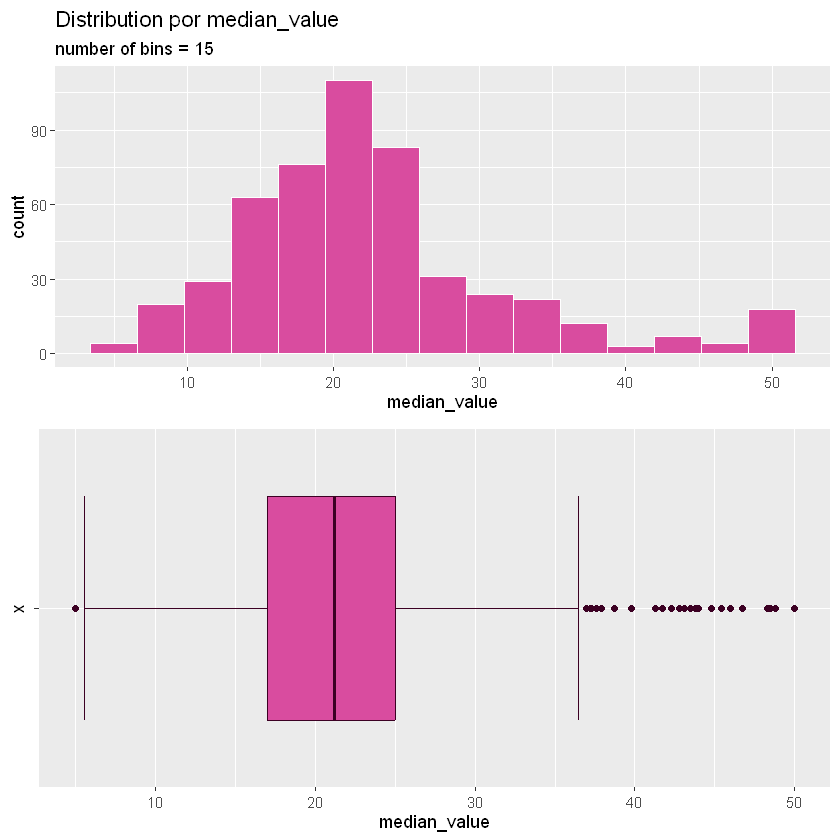

In [8]:
a= ggplot(data = data) + # select the data frame
  aes(x = median_value) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por median_value"  ,subtitle = "number of bins = 15",x = "median_value")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = median_value)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

Looking at the histogram, we can see that our target variable has positive skewness because the distribution tail extends toward high values. In addition, most values are concentrated in the range from 15 to 25.

Regarding the boxplot, the presence of many outliers above approximately 36 stands out. We also have a narrow IQR (interquartile range), indicating that most of our data are quite concentrated.

Finally, we can see that the median (the central black line in the boxplot) and the mode (the highest bar in the histogram) are very similar values.

### Predictor variables

#### Quantitative variables

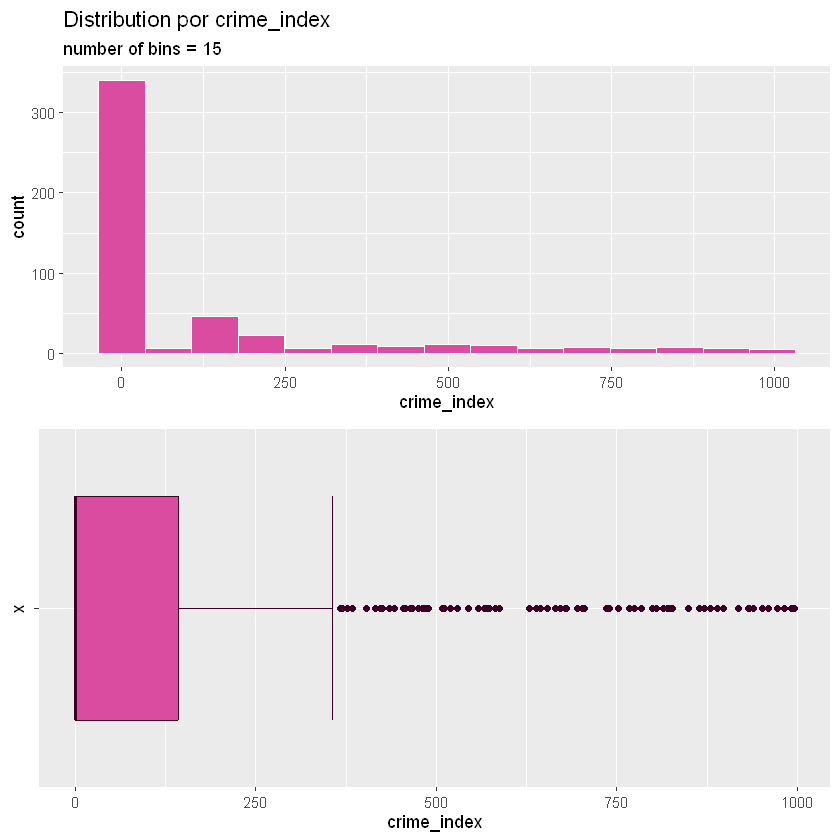

In [9]:
a= ggplot(data = data) + # select the data frame
  aes(x = crime_index) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por crime_index"  ,subtitle = "number of bins = 15",x = "crime_index")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = crime_index)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

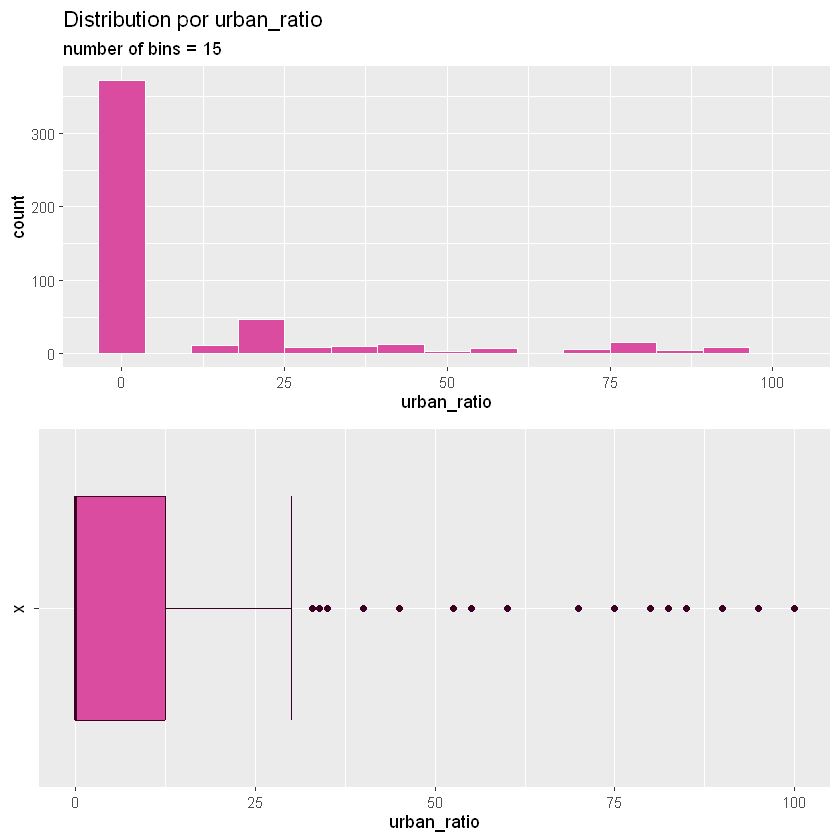

In [10]:
a= ggplot(data = data) + # select the data frame
  aes(x = urban_ratio) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por urban_ratio"  ,subtitle = "number of bins = 15",x = "urban_ratio")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = urban_ratio)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

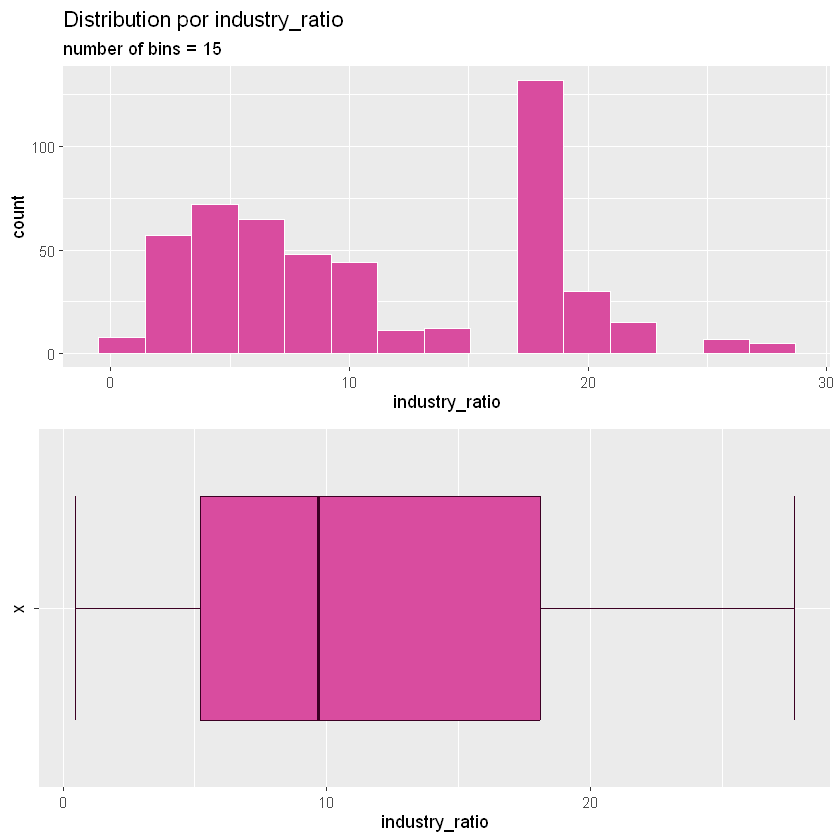

In [11]:
a= ggplot(data = data) + # select the data frame
  aes(x = industry_ratio) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por industry_ratio"  ,subtitle = "number of bins = 15",x = "industry_ratio")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = industry_ratio)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

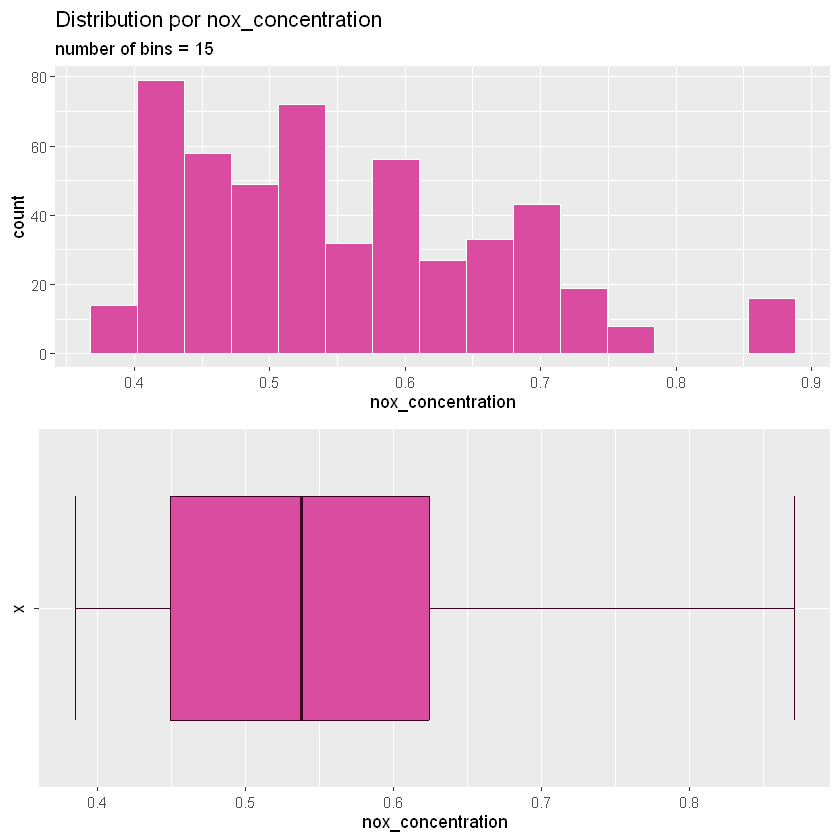

In [12]:
a= ggplot(data = data) + # select the data frame
  aes(x = nox_concentration) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por nox_concentration"  ,subtitle = "number of bins = 15",x = "nox_concentration")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = nox_concentration)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

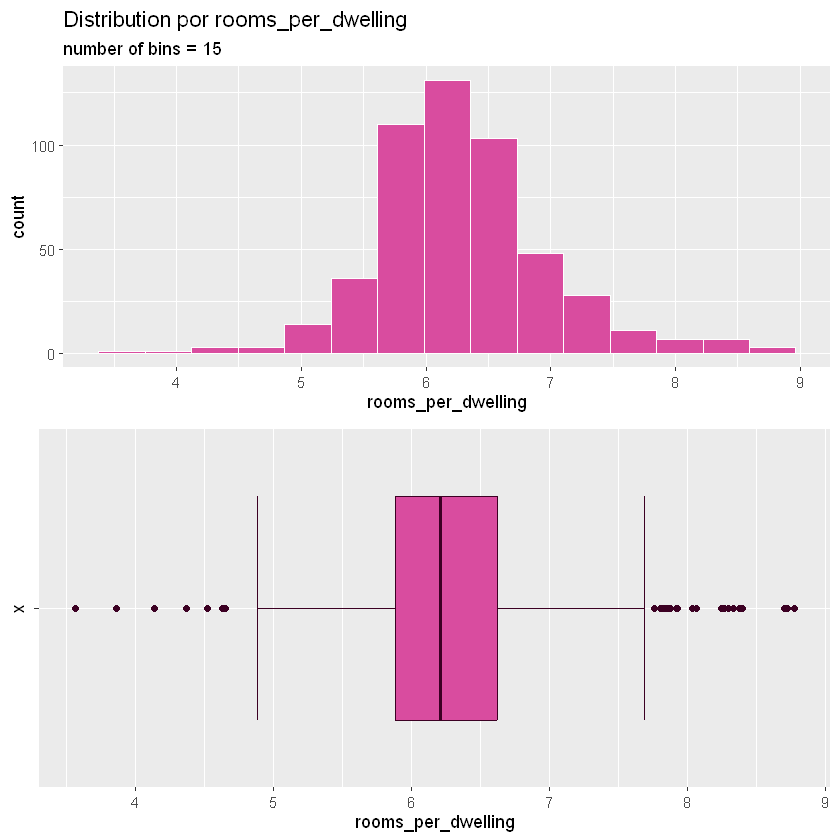

In [13]:
a= ggplot(data = data) + # select the data frame
  aes(x = rooms_per_dwelling) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por rooms_per_dwelling"  ,subtitle = "number of bins = 15",x = "rooms_per_dwelling")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = rooms_per_dwelling)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

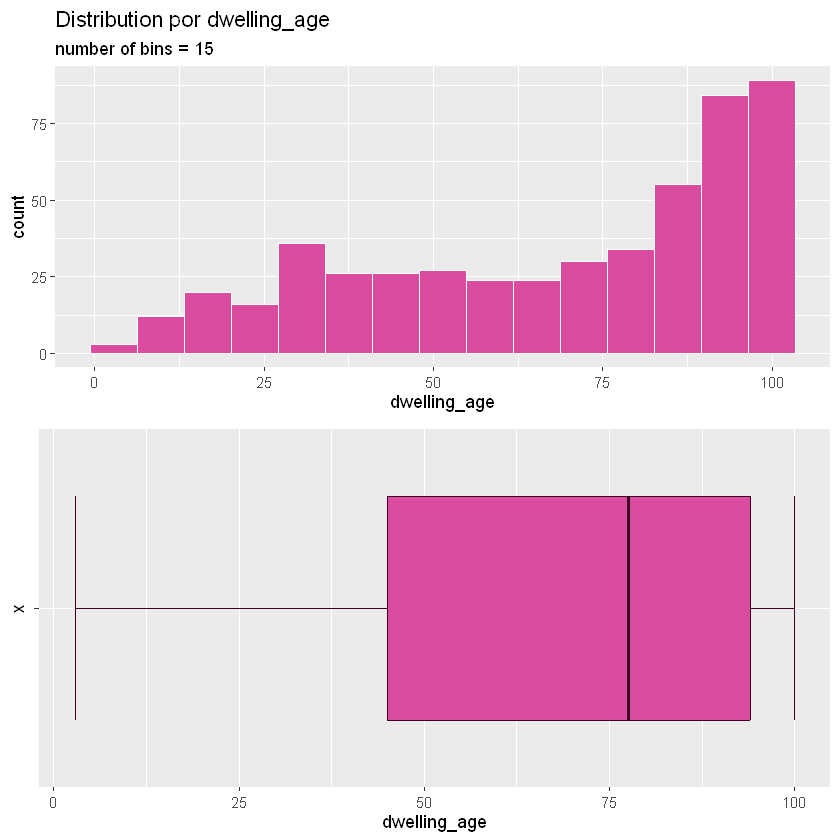

In [14]:
a= ggplot(data = data) + # select the data frame
  aes(x = dwelling_age) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por dwelling_age"  ,subtitle = "number of bins = 15",x = "dwelling_age")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = dwelling_age)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

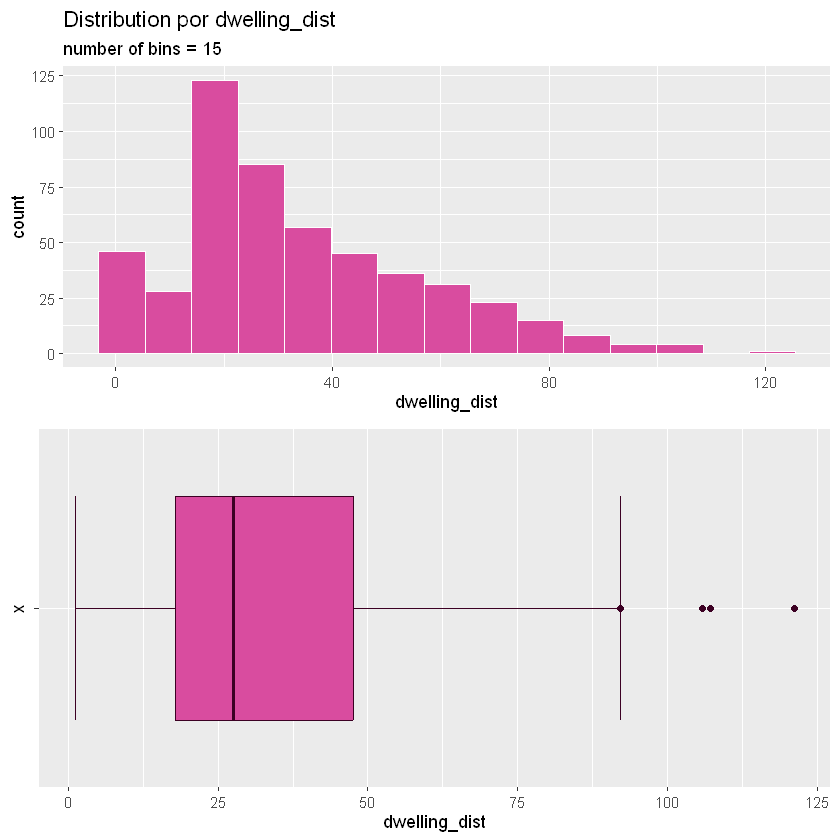

In [15]:
a= ggplot(data = data) + # select the data frame
  aes(x = dwelling_dist) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por dwelling_dist"  ,subtitle = "number of bins = 15",x = "dwelling_dist")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = dwelling_dist)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

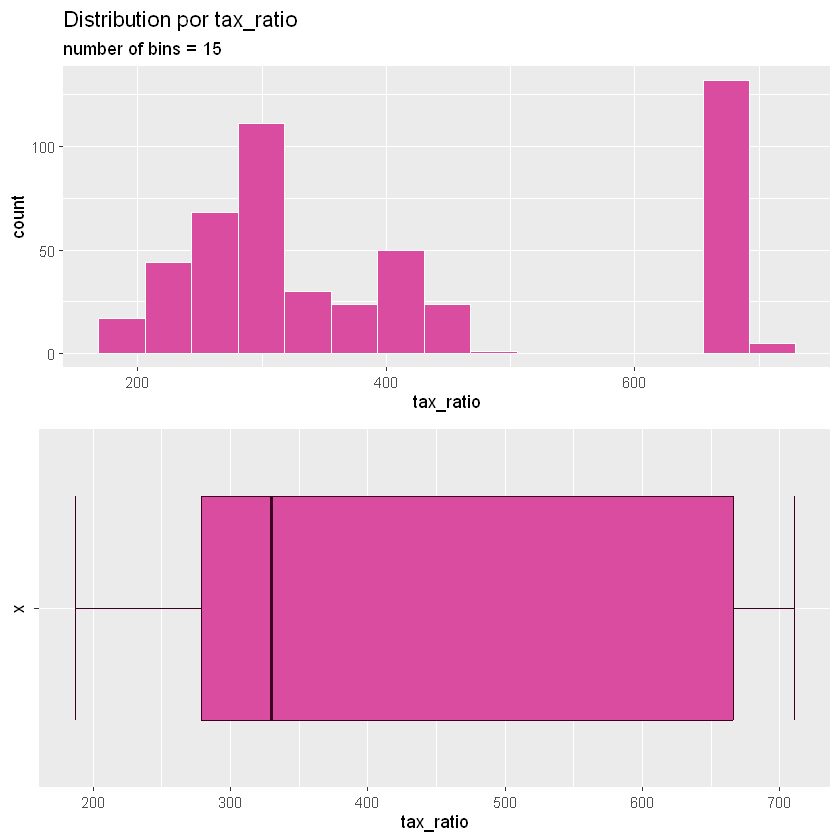

In [16]:
a= ggplot(data = data) + # select the data frame
  aes(x = tax_ratio) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por tax_ratio"  ,subtitle = "number of bins = 15",x = "tax_ratio")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = tax_ratio)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

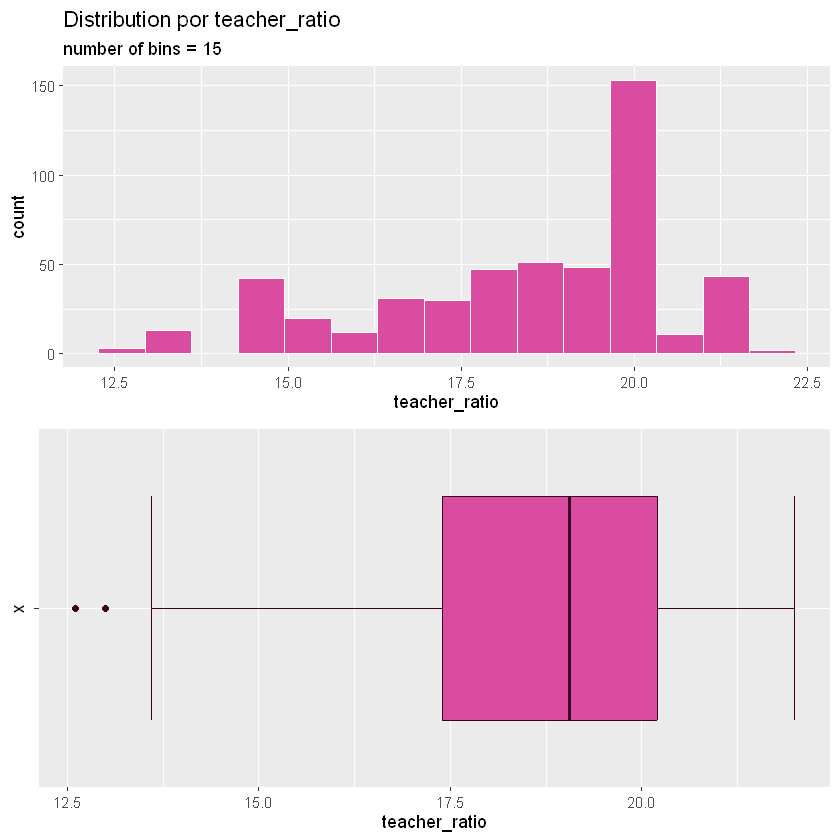

In [17]:
a= ggplot(data = data) + # select the data frame
  aes(x = teacher_ratio) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por teacher_ratio"  ,subtitle = "number of bins = 15",x = "teacher_ratio")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = teacher_ratio)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

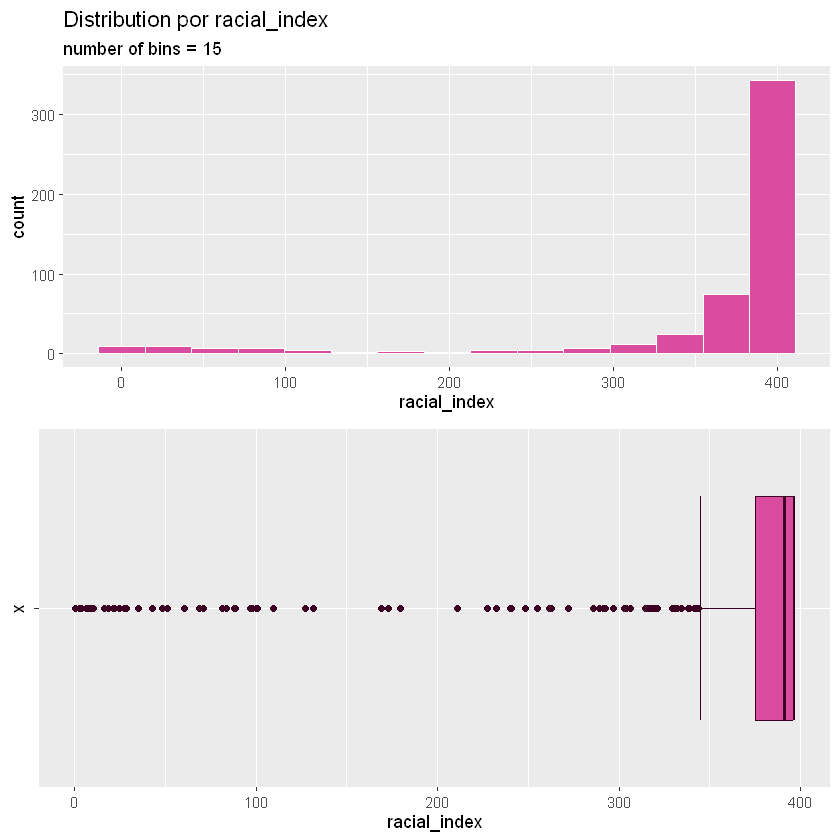

In [18]:
a= ggplot(data = data) + # select the data frame
  aes(x = racial_index) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por racial_index"  ,subtitle = "number of bins = 15",x = "racial_index")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = racial_index)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

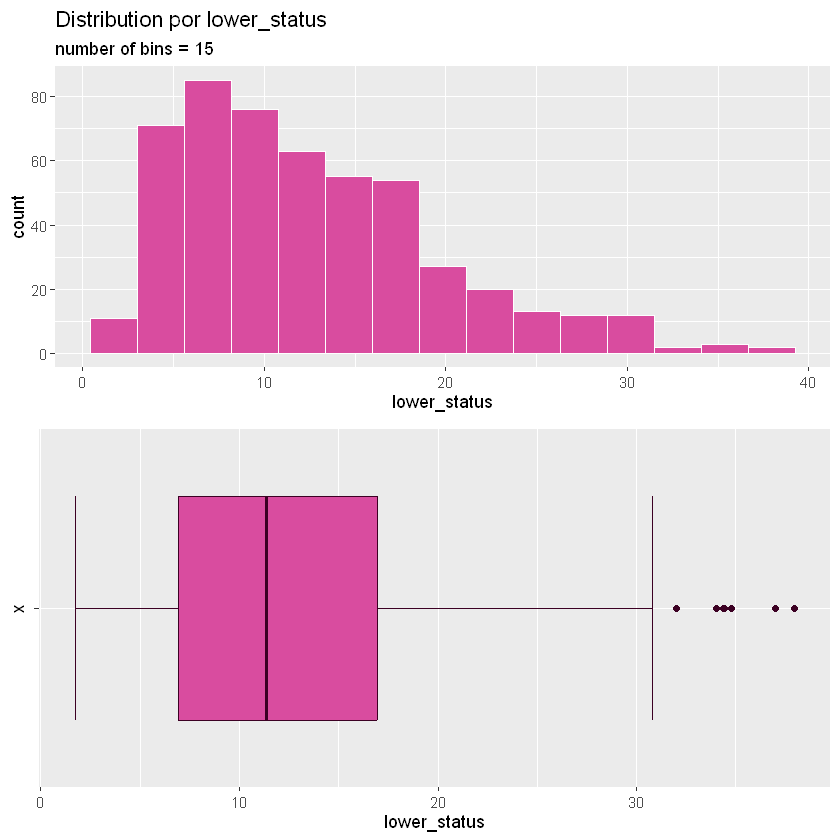

In [19]:
a= ggplot(data = data) + # select the data frame
  aes(x = lower_status) + #specify the variable
  geom_histogram(bins = 15 ,fill = "#d94c9f",color = "white") + #outline color
  labs(title="Distribution por lower_status"  ,subtitle = "number of bins = 15",x = "lower_status")  #x-axis variable name
b= ggplot(data = data, aes(x = "", y = lower_status)) +
       stat_boxplot(geom = "errorbar" ,color = "#3c0023") +
       geom_boxplot(fill = "#d94c9f",color = "#3c0023") +
       coord_flip() # Horizontal boxplot
grid.arrange(a,b)

Reviewing the histograms, we can see that most of our quantitative predictor variables do not appear to follow a normal distribution and show strong skewness. Another notable point from the boxplots is the large presence of outliers in variables such as `racial_index`, `rooms_per_dwelling`, `urban_ratio`, and `crime_index`.

#### Qualitative variables

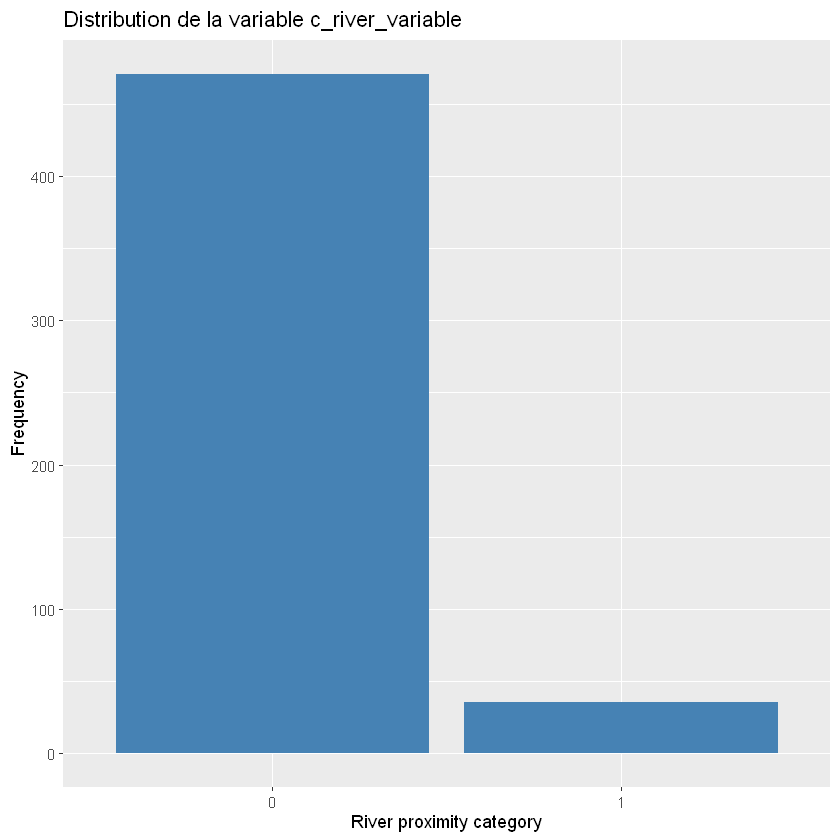

In [20]:
ggplot(data, aes(x = factor(c_river_variable))) +
  geom_bar(fill = "steelblue") +
  labs(
    title = "Distribution de la variable c_river_variable",
    x = "River proximity category",
    y = "Frequency"
  )

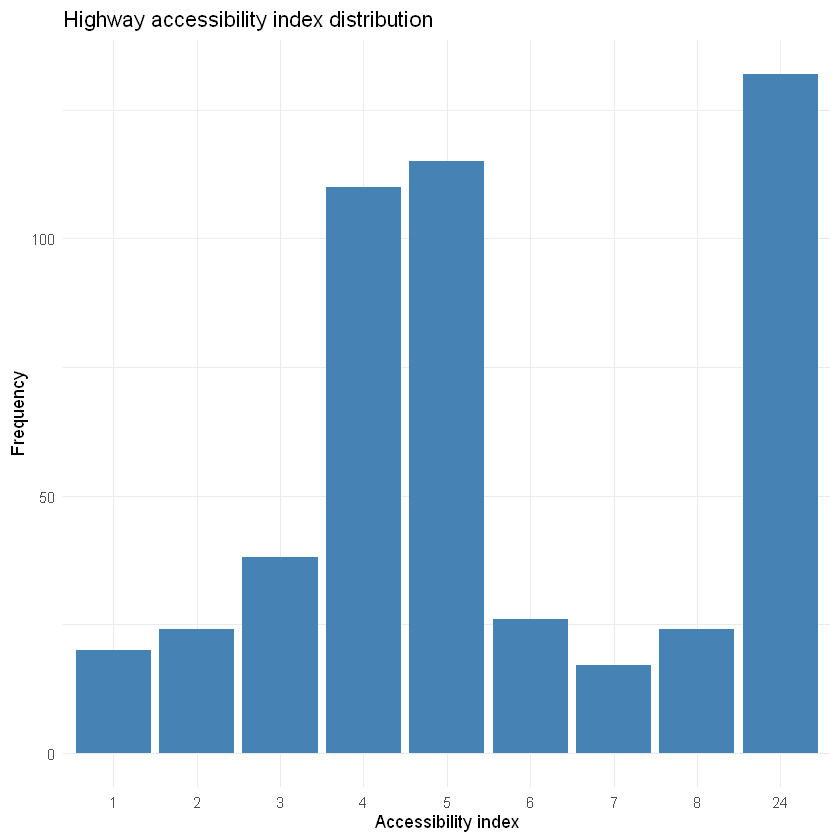

In [21]:
ggplot(data, aes(x = factor(highway_index))) +
  geom_bar(fill = "steelblue") +
  labs(
    title = "Highway accessibility index distribution",
    x = "Accessibility index",
    y = "Frequency"
  ) +
  theme_minimal()

For both our binary qualitative variable, `c_river_variable`, and our ordinal qualitative variable, `highway_index`, we can see that they are quite unbalanced; that is, the categories do not have similar frequencies.

## 2. Correlation and principal component analysis

Once we have visualized our data, we will take our EDA one step further and examine how our quantitative predictor variables are distributed with respect to `median_value`. We will use *scatter plots* for this purpose.

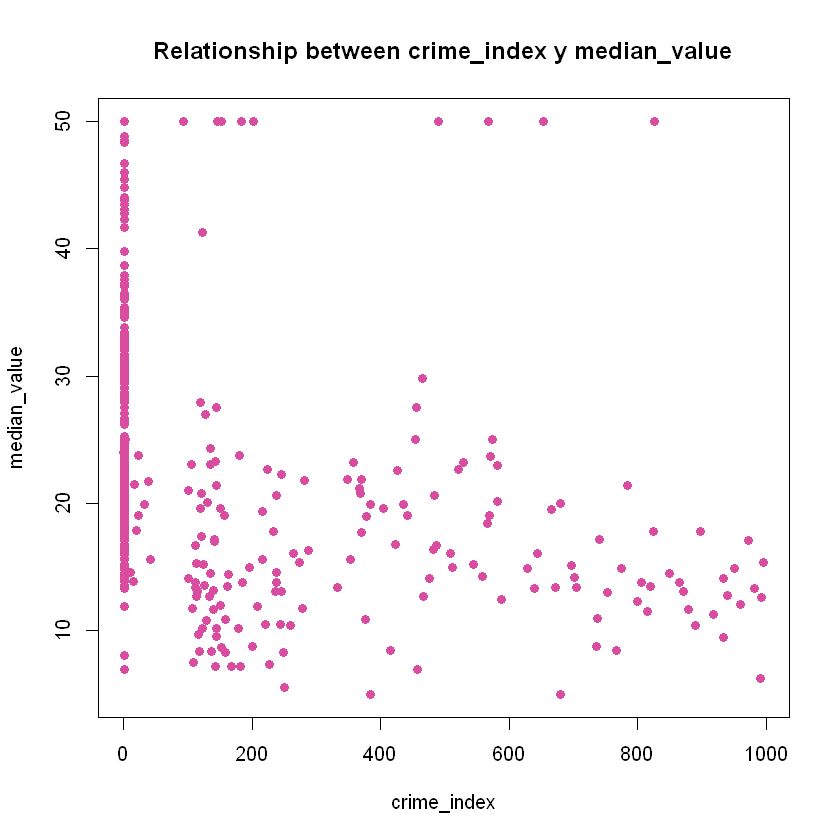

In [22]:
plot(data$crime_index, data$median_value, main = "Relationship between crime_index y median_value", xlab = "crime_index", ylab = "median_value", pch = 19, col = "#d94c9f")

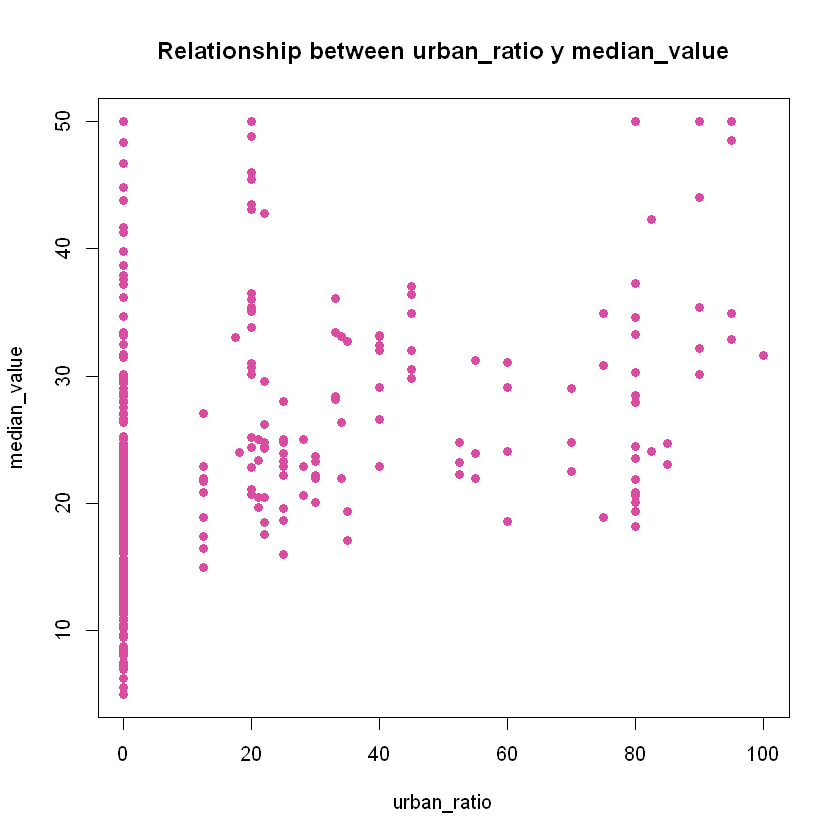

In [23]:
plot(data$urban_ratio, data$median_value, main = "Relationship between urban_ratio y median_value", xlab = "urban_ratio", ylab = "median_value", pch = 19, col = "#d94c9f")

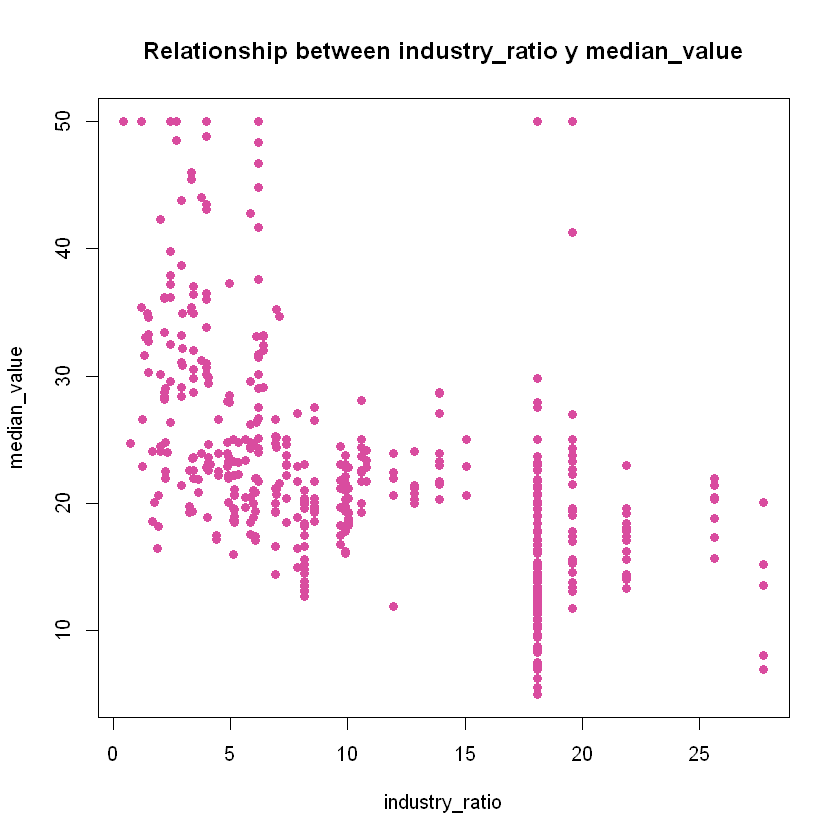

In [24]:
plot(data$industry_ratio, data$median_value, main = "Relationship between industry_ratio y median_value", xlab = "industry_ratio", ylab = "median_value", pch = 19, col = "#d94c9f")

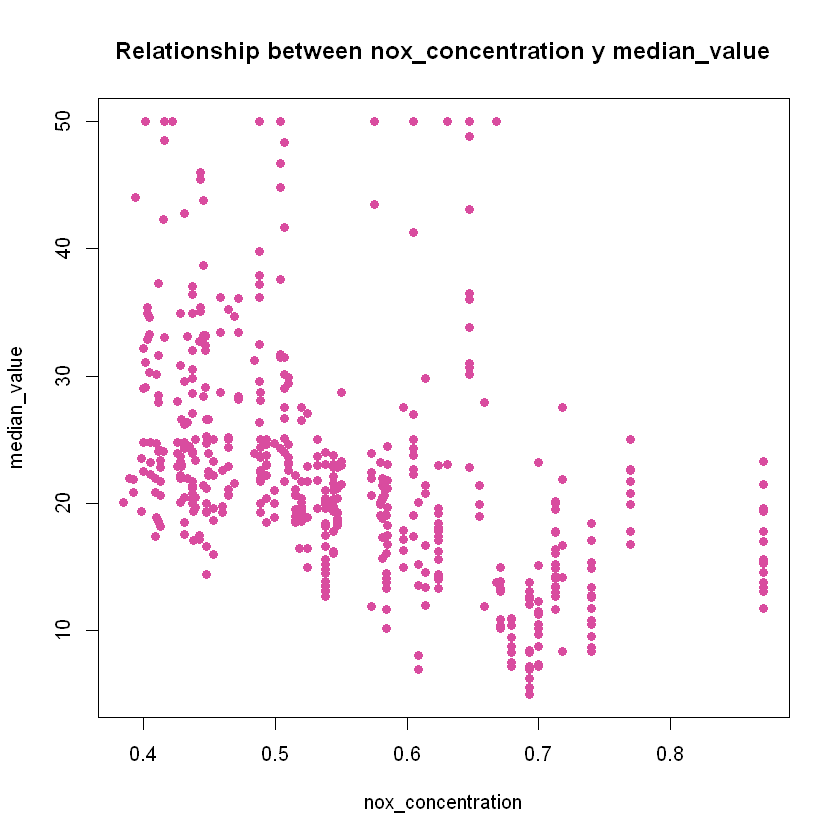

In [25]:
plot(data$nox_concentration, data$median_value, main = "Relationship between nox_concentration y median_value", xlab = "nox_concentration", ylab = "median_value", pch = 19, col = "#d94c9f")

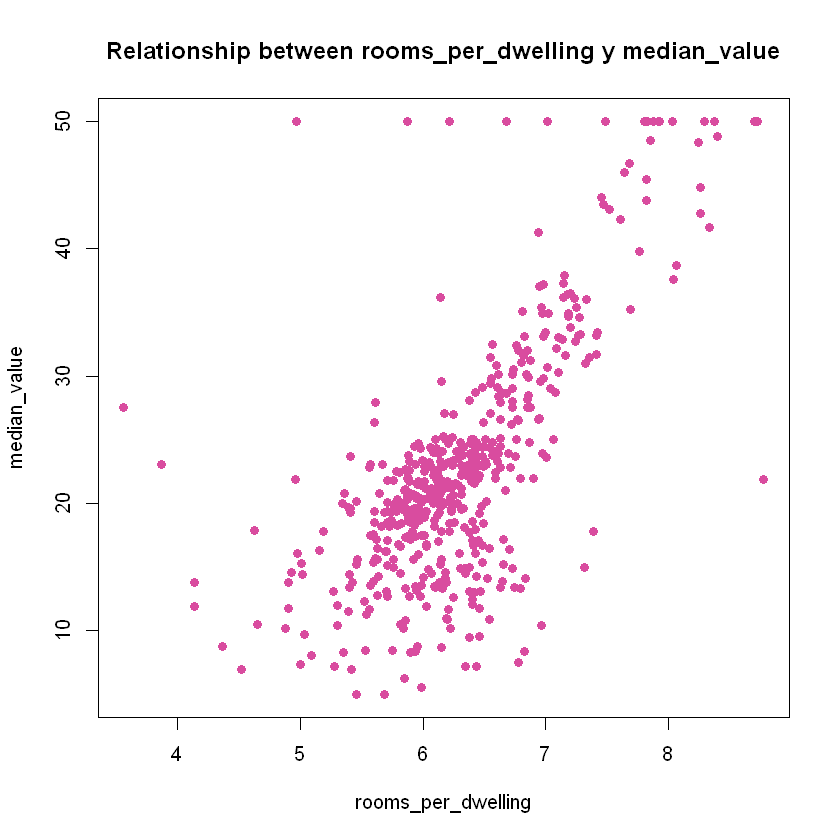

In [26]:
plot(data$rooms_per_dwelling, data$median_value, main = "Relationship between rooms_per_dwelling y median_value", xlab = "rooms_per_dwelling", ylab = "median_value", pch = 19, col = "#d94c9f")

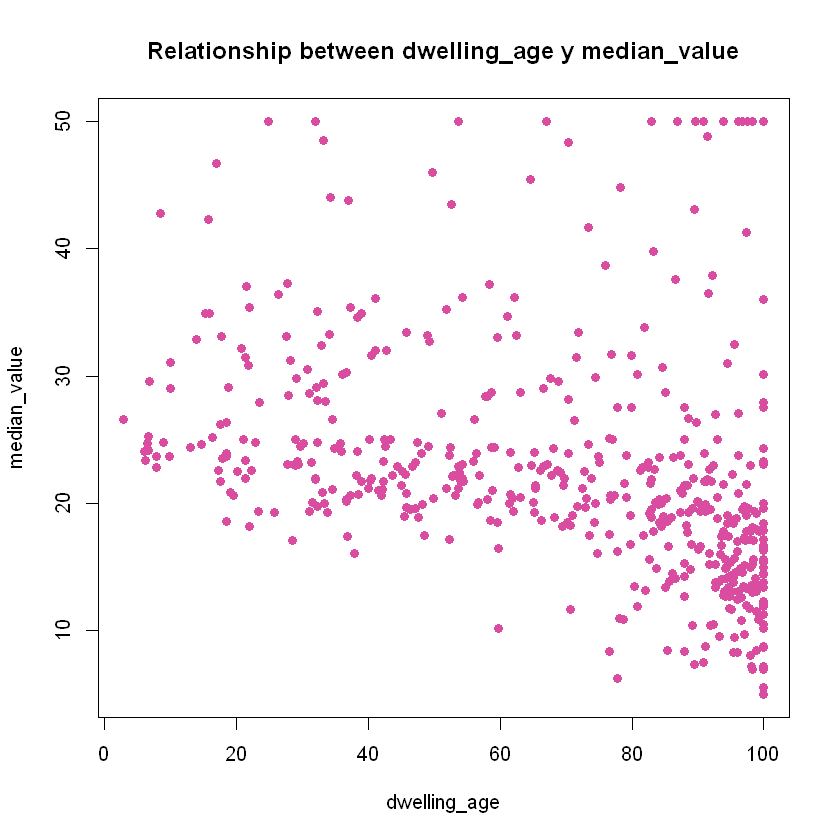

In [27]:
plot(data$dwelling_age, data$median_value, main = "Relationship between dwelling_age y median_value", xlab = "dwelling_age", ylab = "median_value", pch = 19, col = "#d94c9f")

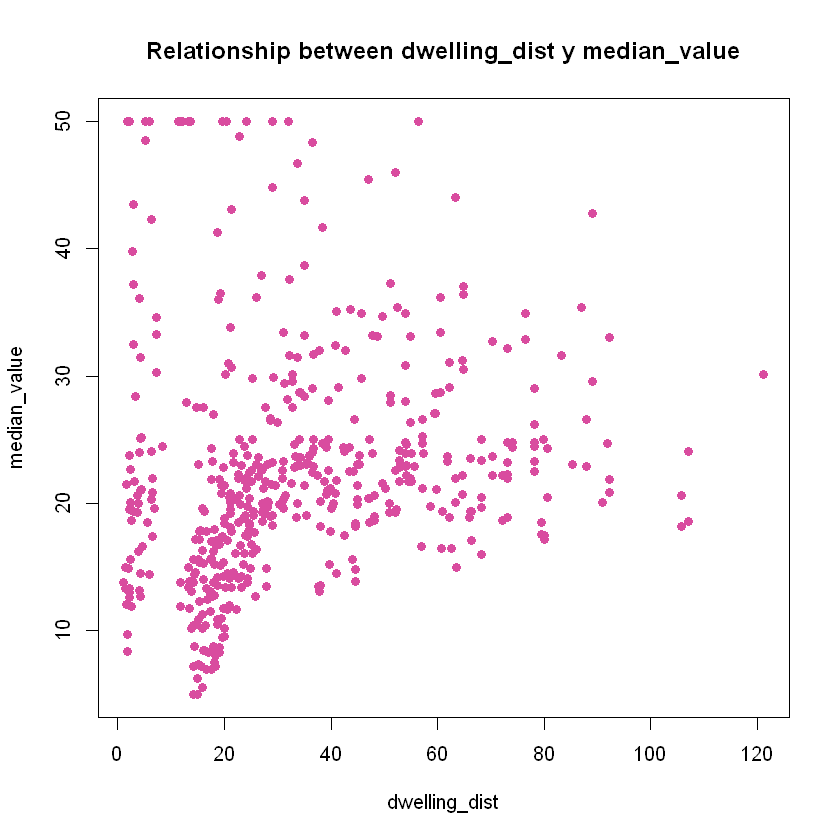

In [28]:
plot(data$dwelling_dist, data$median_value, main = "Relationship between dwelling_dist y median_value", xlab = "dwelling_dist", ylab = "median_value", pch = 19, col = "#d94c9f")

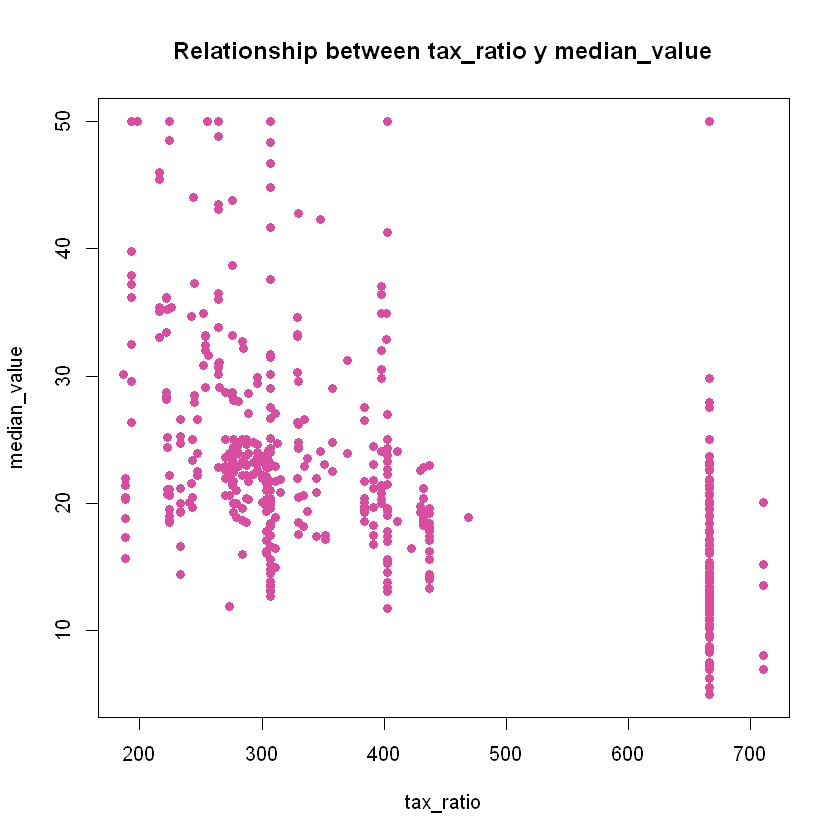

In [29]:
plot(data$tax_ratio, data$median_value, main = "Relationship between tax_ratio y median_value", xlab = "tax_ratio", ylab = "median_value", pch = 19, col = "#d94c9f")

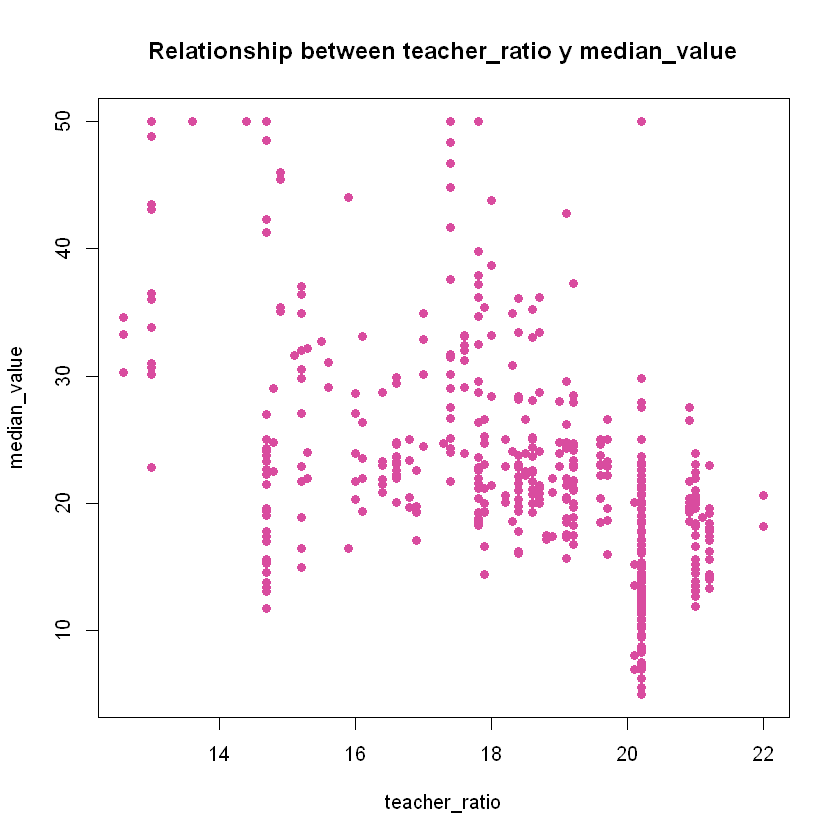

In [30]:
plot(data$teacher_ratio, data$median_value, main = "Relationship between teacher_ratio y median_value", xlab = "teacher_ratio", ylab = "median_value", pch = 19, col = "#d94c9f")

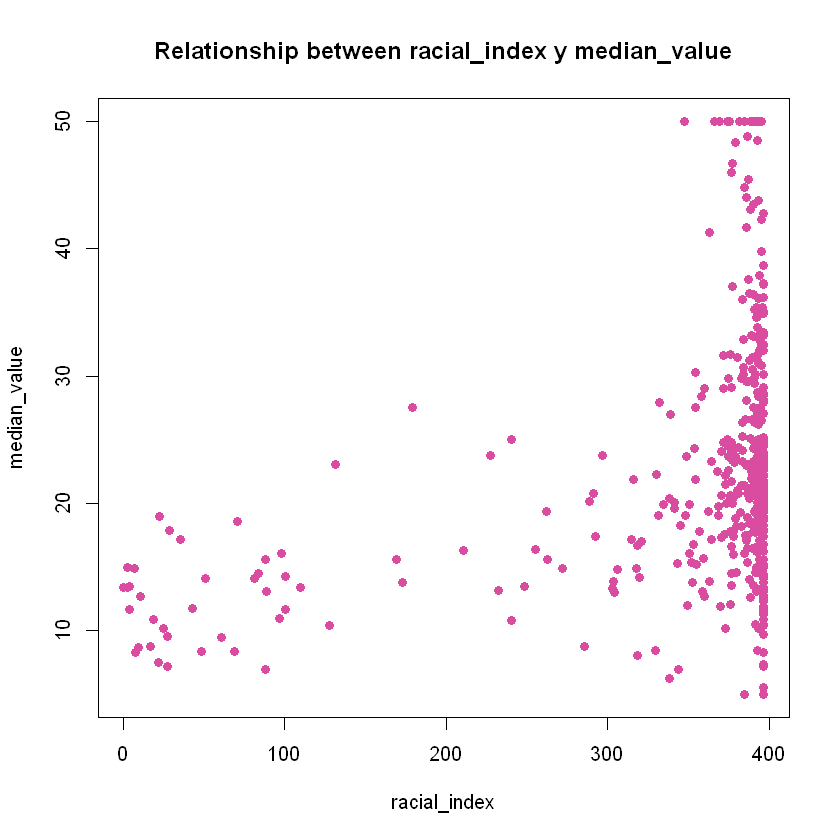

In [31]:
plot(data$racial_index, data$median_value, main = "Relationship between racial_index y median_value", xlab = "racial_index", ylab = "median_value", pch = 19, col = "#d94c9f")

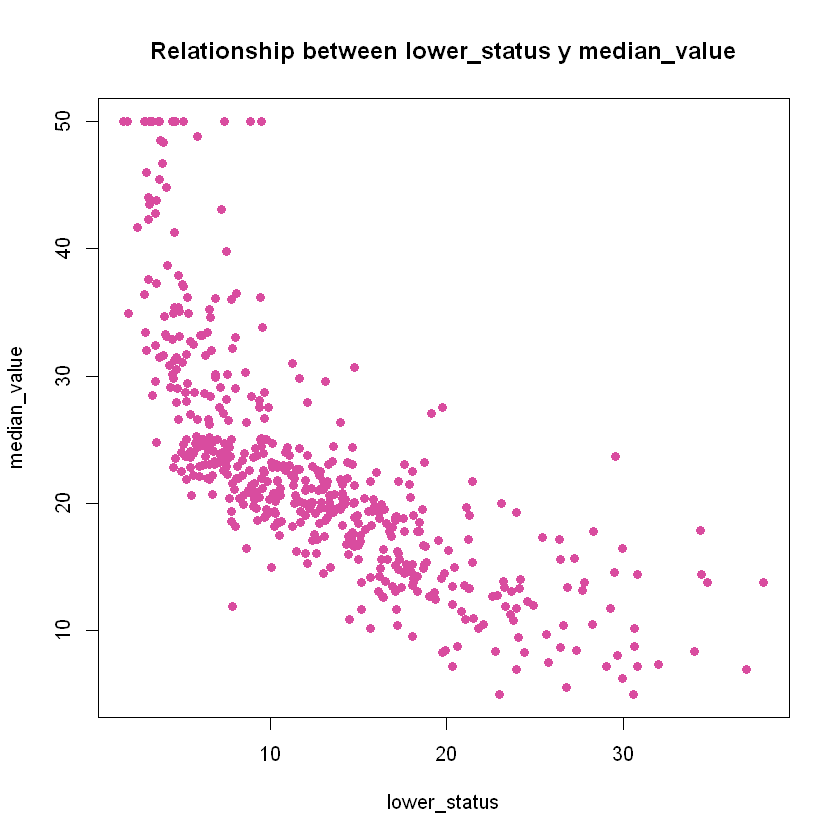

In [32]:
plot(data$lower_status, data$median_value, main = "Relationship between lower_status y median_value", xlab = "lower_status", ylab = "median_value", pch = 19, col = "#d94c9f")

The plots we have just generated are useful because they help us detect which variables appear to have a linear relationship with our target variable. At first glance, we observe a possible negative linear relationship with `lower_status` and a positive linear relationship with `rooms_per_dwelling`: if the percentage of the low-income population increases, the median house price tends to decrease; on the other hand, if the average number of rooms per dwelling increases, its price tends to increase. These findings are logical.

To explore these relationships further, we will use the correlation matrix. It will show not only whether there are linear relationships with our target variable, but also relationships among our predictor variables. We will do this only with our quantitative variables.

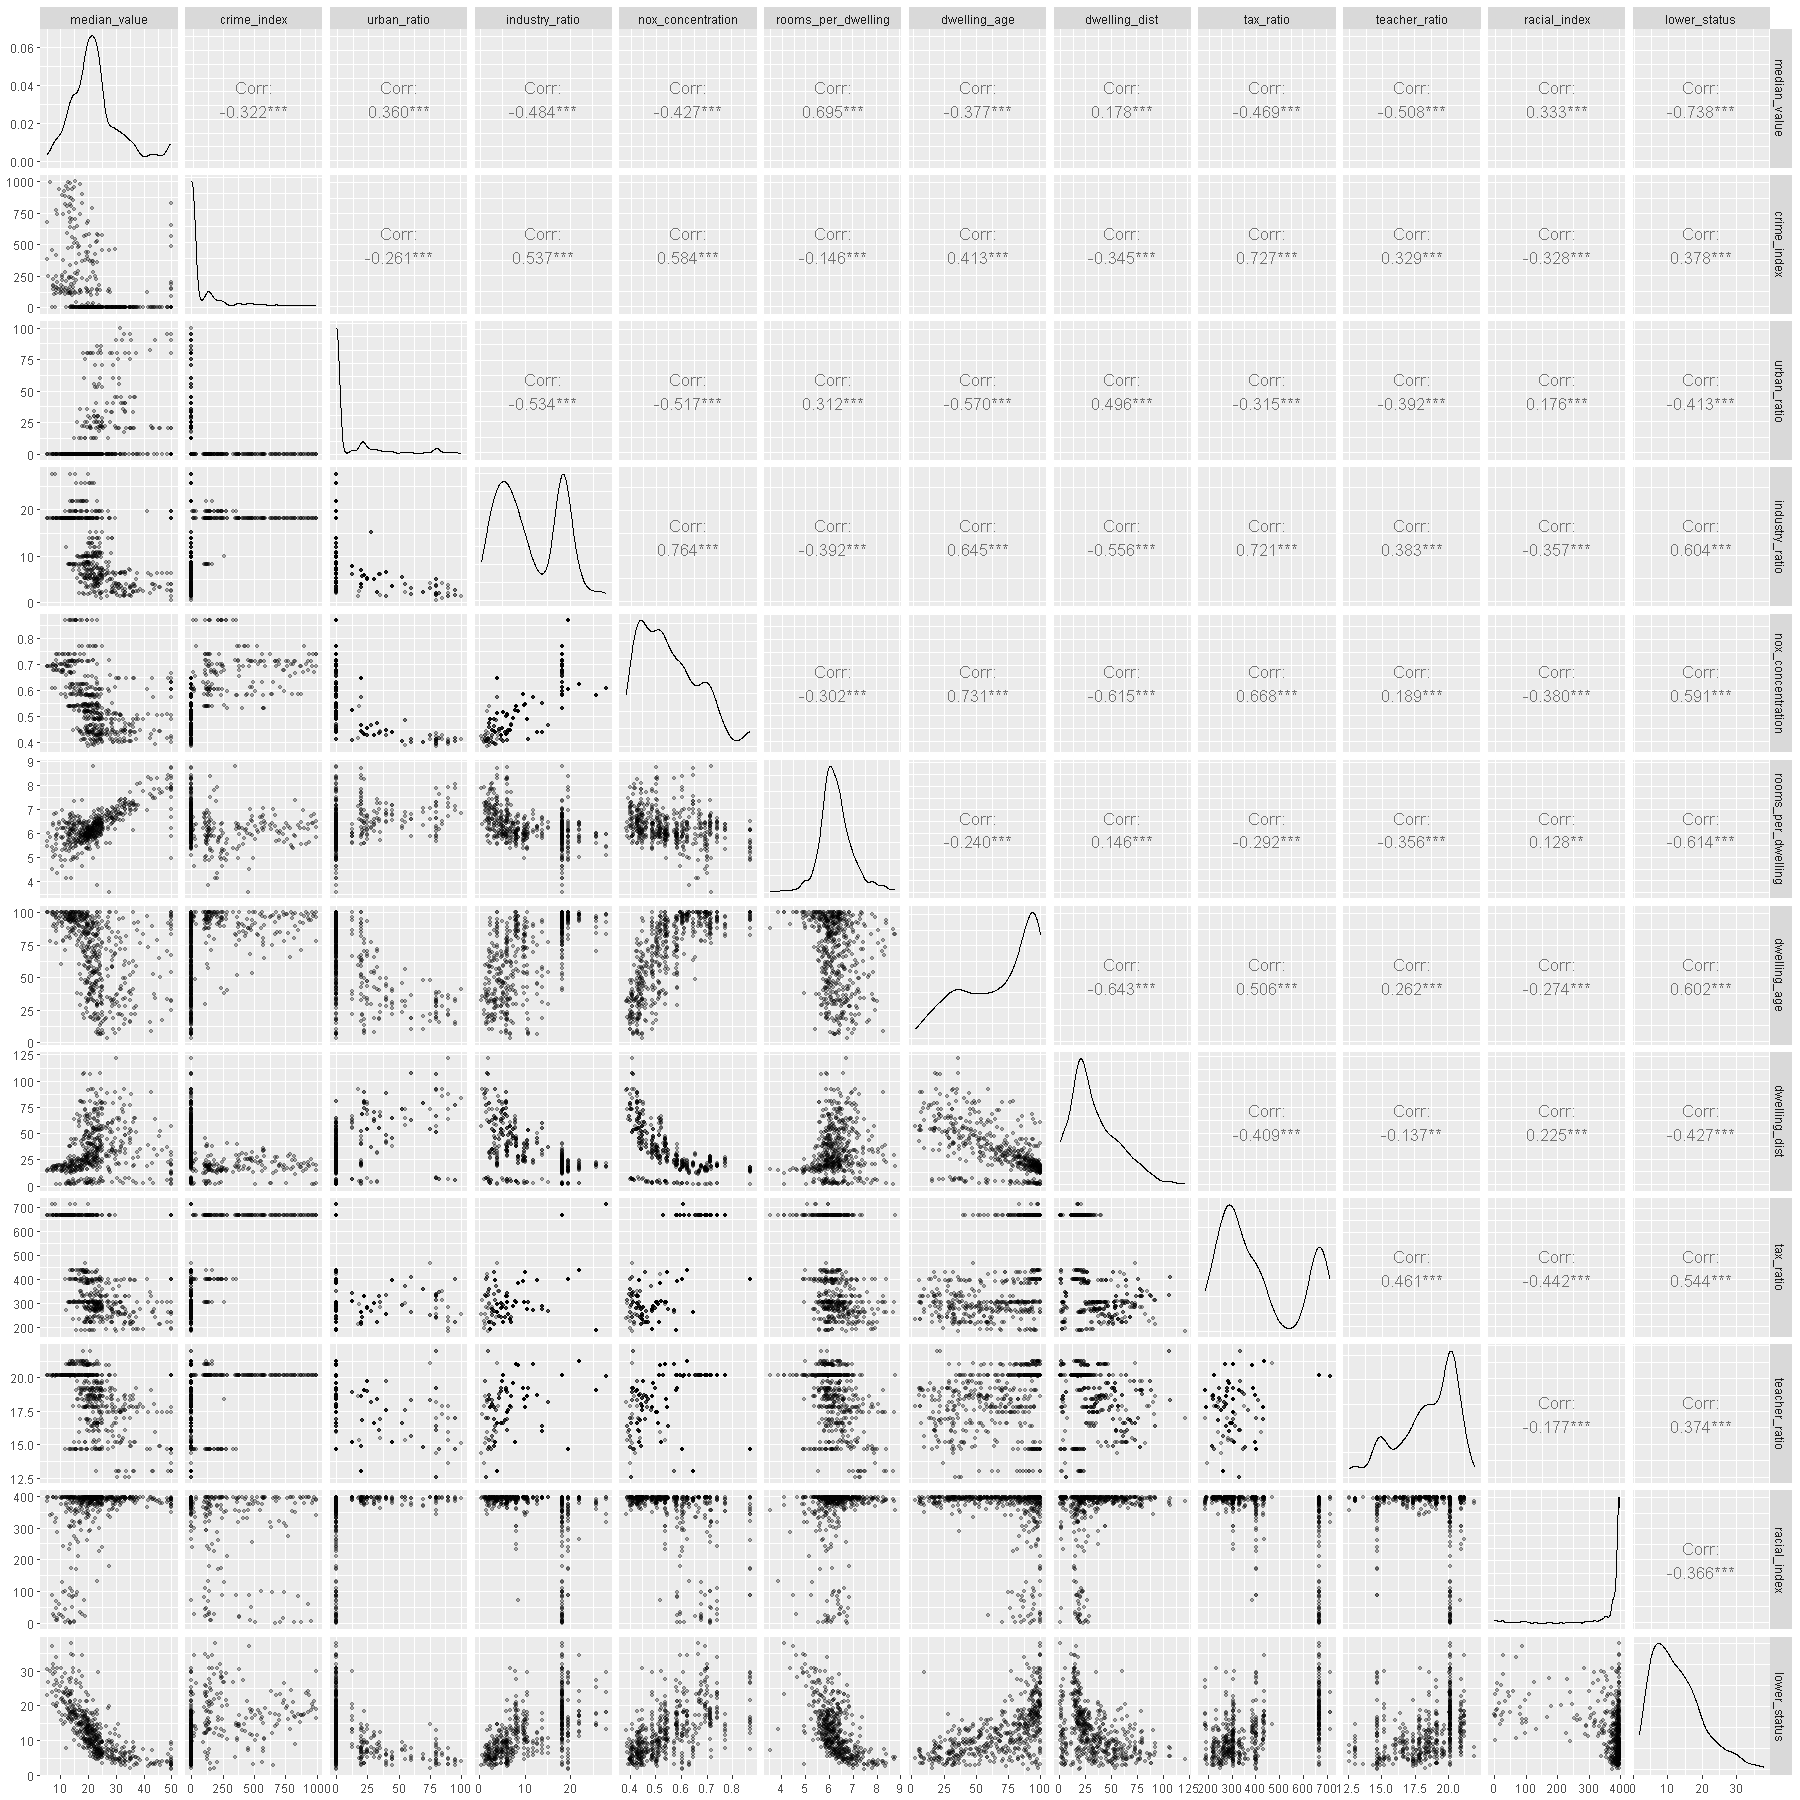

In [33]:
data_num <- data[, c("median_value", "crime_index", "urban_ratio", 
                     "industry_ratio", "nox_concentration", "rooms_per_dwelling", 
                     "dwelling_age", "dwelling_dist", "tax_ratio", 
                     "teacher_ratio", "racial_index", "lower_status")]

# ampliar el tamaño del lienzo en Jupyter Notebook (15x15 pulgadas)
options(repr.plot.width = 15, repr.plot.height = 15)

ggpairs(
  data_num,
  lower = list(continuous = wrap("points", alpha = 0.3, size = 0.8)),
  upper = list(continuous = wrap("cor", size = 3.5))
) + theme_gray(base_size = 9)

This plot is very helpful because it shows the variable distributions, the *scatter plots*, and the correlation calculations. A careful analysis reveals two things:
* Some variables have a strong correlation with `median_value`, especially `lower_status` (-0.74) and `rooms_per_dwelling` (0.70).
* There is some collinearity, meaning that independent variables are related to one another. Examples include `tax_ratio` and `crime_index` (0.727), `nox_concentration` and `industry_ratio` (0.764), and `tax_ratio` and `industry_ratio` (0.721).


Let's now perform an analysis of the principal components.

In [34]:
data_acp <- data_num[, -1]  # Exclude the median_value variable for PCA
names(data_acp) # check that the median_value variable was excluded correctly

[1] "crime_index"        "urban_ratio"        "industry_ratio"    
 [4] "nox_concentration"  "rooms_per_dwelling" "dwelling_age"      
 [7] "dwelling_dist"      "tax_ratio"          "teacher_ratio"     
[10] "racial_index"       "lower_status"

Importance of components:
                          Comp.1    Comp.2    Comp.3     Comp.4     Comp.5
Standard deviation     2.3294643 1.1037864 1.0630399 0.90989360 0.83076080
Proportion of Variance 0.4933094 0.1107586 0.1027322 0.07526422 0.06274214
Cumulative Proportion  0.4933094 0.6040680 0.7068002 0.78206442 0.84480655
                           Comp.6    Comp.7     Comp.8     Comp.9    Comp.10
Standard deviation     0.65330869 0.6098343 0.58521836 0.46999258 0.41782940
Proportion of Variance 0.03880111 0.0338089 0.03113459 0.02008118 0.01587104
Cumulative Proportion  0.88360767 0.9174166 0.94855116 0.96863235 0.98450338
                          Comp.11
Standard deviation     0.41287139
Proportion of Variance 0.01549662
Cumulative Proportion  1.00000000

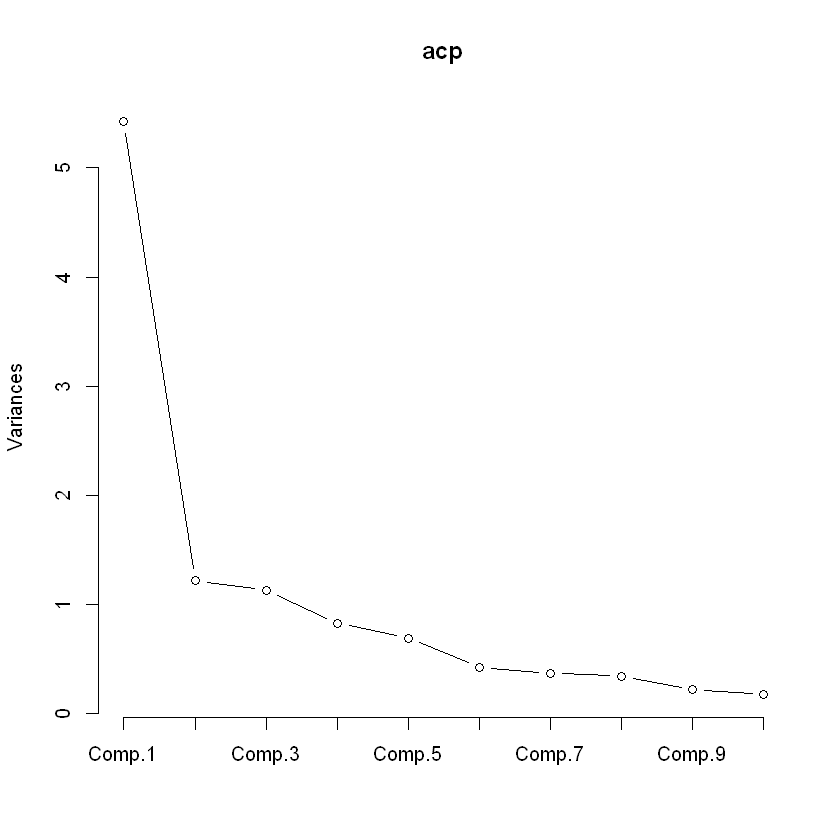

In [35]:
acp = princomp(data_acp,cor=TRUE)
summary(acp)

options(repr.plot.width = NULL, repr.plot.height = NULL) # restore the canvas size to the default values
plot(acp, type = "lines")

We can see in the *scree plot* that there is a sharp drop between the first and second components, after which the decline becomes smoother. This means that these are the two components explaining most of the variation (60.41%). Therefore, the dimensionality of the dataset could be reduced to these two components. If we wanted to explain more variation, we could add component 3 and obtain a cumulative percentage of 70.68%, although this would reduce dimensionality less.

In [36]:
loadings(acp) # show the weights of each variable in each principal component


Loadings:
                   Comp.1 Comp.2 Comp.3 Comp.4 Comp.5 Comp.6 Comp.7 Comp.8
crime_index         0.288  0.149  0.457  0.261  0.313  0.192  0.106  0.591
urban_ratio        -0.279         0.429 -0.302  0.408 -0.572        -0.200
industry_ratio      0.374                       0.110  0.173        -0.665
nox_concentration   0.370  0.246        -0.109  0.172  0.231 -0.137 -0.125
rooms_per_dwelling -0.208  0.631  0.179  0.347 -0.261 -0.193 -0.322       
dwelling_age        0.342  0.210 -0.278               -0.257 -0.567  0.119
dwelling_dist      -0.290 -0.357  0.331                0.461 -0.674       
tax_ratio           0.347         0.404  0.116  0.178               -0.247
teacher_ratio       0.213 -0.512  0.158  0.557 -0.318 -0.367              
racial_index       -0.207        -0.435  0.501  0.690                     
lower_status        0.332 -0.273        -0.363  0.113 -0.311 -0.280  0.236
                   Comp.9 Comp.10 Comp.11
crime_index                0.347         
urban

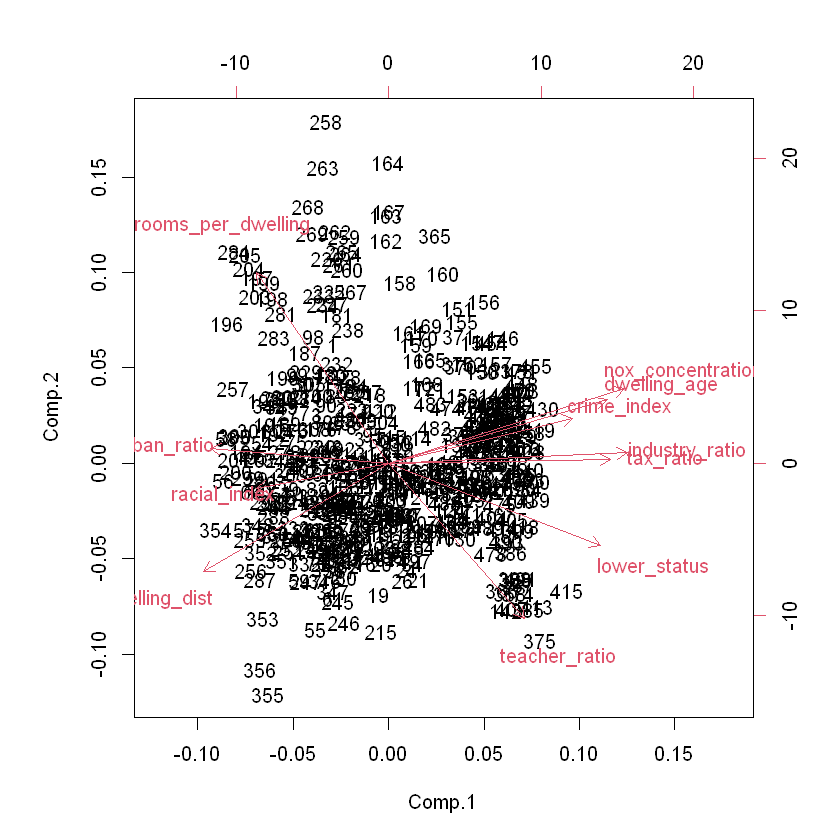

In [37]:
biplot(acp)

In summary:
* There are 11 components, with the first 2 explaining the largest proportion of the variation.
* Component 1 explains 49.33% of the variation, with `industry_ratio` (0.374) and `nox_concentration` (0.370) standing out most.
* Component 2 explains 11.08% of the variation, with `rooms_per_dwelling` (0.631) and `teacher_ratio` (-0.512) standing out most.

## 3. ANOVA analysis

After analyzing how our quantitative variables influence `median_value`, we will see whether the qualitative variables do as well. To do this, we will use the ANOVA test with `c_river_variable` and `highway_index`.

In [38]:
anova = aov(median_value ~ c_river_variable, data = data)
summary(anova)

                  Df Sum Sq Mean Sq F value   Pr(>F)    
c_river_variable   1   1312  1312.1   15.97 7.39e-05 ***
Residuals        504  41404    82.2                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

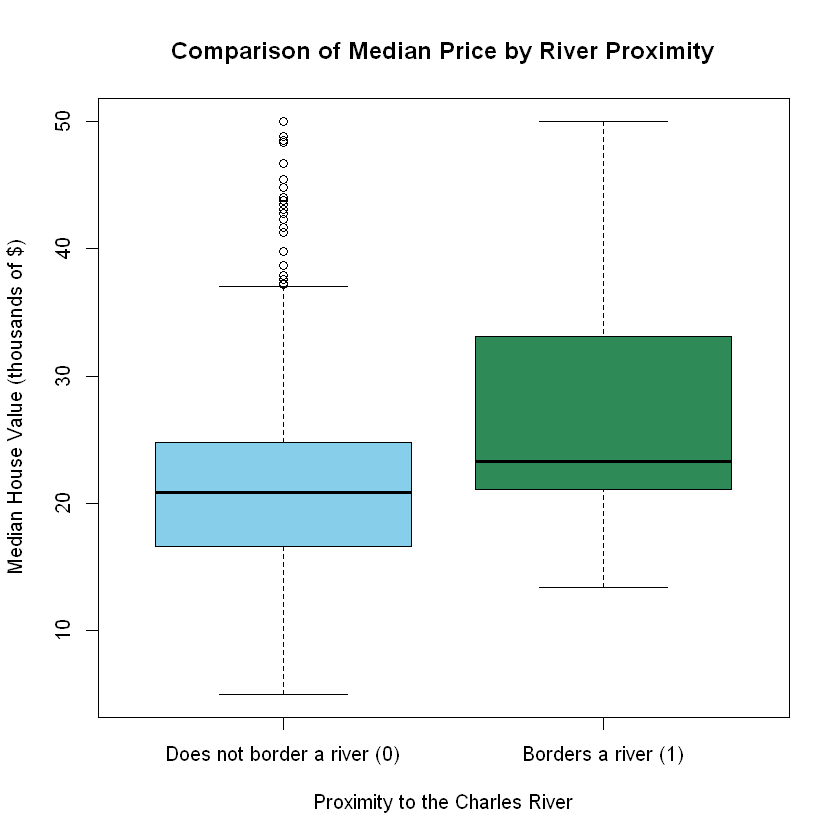

In [39]:
boxplot(median_value ~ c_river_variable, 
        data = data,
        names = c("Does not border a river (0)", "Borders a river (1)"),
        col = c("skyblue", "seagreen"),
        main = "Comparison of Median Price by River Proximity",
        xlab = "Proximity to the Charles River",
        ylab = "Median House Value (thousands of $)")

In [40]:
anova = aov(median_value ~ highway_index, data = data)
summary(anova)

               Df Sum Sq Mean Sq F value Pr(>F)    
highway_index   1   6221    6221   85.91 <2e-16 ***
Residuals     504  36495      72                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

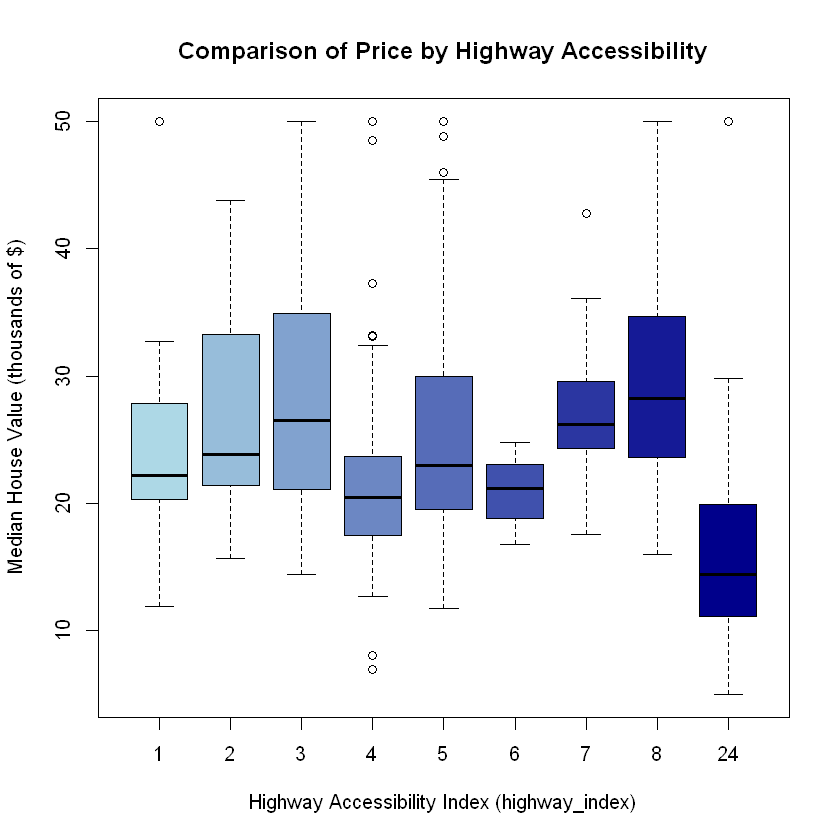

In [42]:
boxplot(median_value ~ highway_index, 
        data = data,
        col = colorRampPalette(c("lightblue", "darkblue"))(length(unique(data$highway_index))),
        main = "Comparison of Price by Highway Accessibility",
        xlab = "Highway Accessibility Index (highway_index)",
        ylab = "Median House Value (thousands of $)")

After carrying out these two ANOVA tests, we can see that both qualitative variables have statistically significant effects on the target variable, since both have a p-value < 0.05. `highway_index` stands out in particular, with an F statistic = 85.91 (very high) and a p-value = 2e-16 (very low).

The boxplots also help us observe how the price changes across categories. If the house is near the river, it is more expensive; if its `highway_index` = 24, it tends to be cheaper.

## 4. Regression variable selection

After analyzing both quantitative and qualitative variables, we can choose the variables for our regression. We are looking for predictors that help explain `median_value` while minimizing the dimensionality of the regression. The PCA performed earlier was very important because it showed that two independent components explained a large part of the variation. Therefore, we will choose the variables that we believe best represent these components:
* `rooms_per_dwelling`: it had the greatest weight within component 1.
* `lower_status`: it was not the variable with the greatest weight in component 2, but it was very close. In addition, our EDA showed that it had the greatest correlation with the dependent variable.

To finish building our regression, we will determine which qualitative variable improves our model the most. As seen earlier, both are statistically significant. We will therefore fit two regressions and compare them: one with `c_river_variable` and another with `highway_index`.

## 5. Linear regression

We will first split our dataset into training and test sets. We will use the training dataset to determine which model gives us better results.

In [43]:
data_ml = data
set.seed(123)
# split 60% for training and 40% for testing
inTrain = createDataPartition(y = data$median_value
                              ,p = 0.6
                              , list = FALSE
                              , times = 1)

data_train  = data_ml[inTrain, ]
data_test = data_ml[-inTrain, ]

In [44]:
# model with highway_index, rooms_per_dwelling, and lower_status
model1 <- lm(median_value ~ highway_index + rooms_per_dwelling + lower_status, data = data_train)
summary(model1)


Call:
lm(formula = median_value ~ highway_index + rooms_per_dwelling + 
    lower_status, data = data_train)

Residuals:
     Min       1Q   Median       3Q      Max 
-17.3265  -3.4547  -0.9533   1.9220  30.0502 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)        -2.72541    3.88852  -0.701   0.4839    
highway_index      -0.08713    0.04177  -2.086   0.0378 *  
rooms_per_dwelling  5.38976    0.54395   9.909   <2e-16 ***
lower_status       -0.61985    0.06505  -9.529   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 5.52 on 302 degrees of freedom
Multiple R-squared:  0.6589,	Adjusted R-squared:  0.6556 
F-statistic: 194.5 on 3 and 302 DF,  p-value: < 2.2e-16


In [45]:
# model with c_river_variable, rooms_per_dwelling, and lower_status
model2 <- lm(median_value ~ c_river_variable + rooms_per_dwelling + lower_status, data = data_train)
summary(model2)


Call:
lm(formula = median_value ~ c_river_variable + rooms_per_dwelling + 
    lower_status, data = data_train)

Residuals:
     Min       1Q   Median       3Q      Max 
-21.3130  -3.3859  -0.9163   2.0595  27.9735 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)        -0.62711    3.82640  -0.164  0.86993    
c_river_variable    3.49991    1.20458   2.905  0.00394 ** 
rooms_per_dwelling  5.00584    0.53530   9.351  < 2e-16 ***
lower_status       -0.68263    0.05638 -12.108  < 2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 5.484 on 302 degrees of freedom
Multiple R-squared:  0.6634,	Adjusted R-squared:  0.6601 
F-statistic: 198.4 on 3 and 302 DF,  p-value: < 2.2e-16


The model trained with `c_river_variable` is slightly better than the one trained with `highway_index`, since its R-squared and adjusted R-squared are higher, its F statistic is also higher, its RSE is lower, and so on.

In [46]:
# save as the final model
model <- model2

### Regression checks

#### Normality


	Lilliefors (Kolmogorov-Smirnov) normality test

data:  model$residuals
D = 0.11474, p-value = 1.922e-10


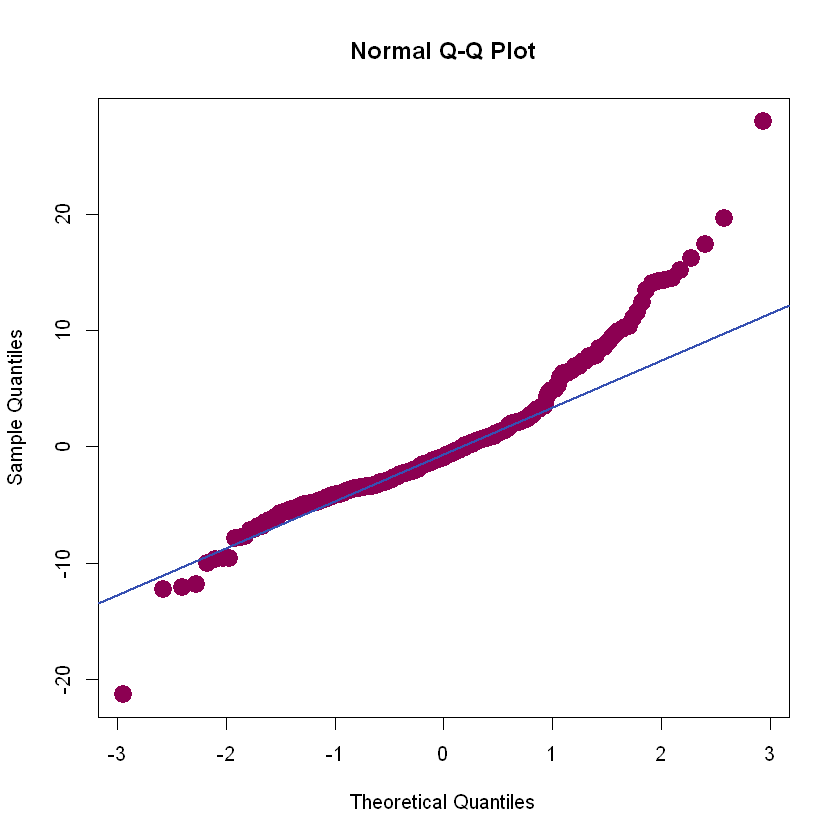

In [47]:
qqnorm(model$residuals,pch =19,col ="#8c0052", cex=2)
qqline(model$residuals , col = "#3650b2", lwd = 2 )

lillie.test(model$residuals)

#### Homoscedasticity


	studentized Breusch-Pagan test

data:  model
BP = 7.1576, df = 3, p-value = 0.06704


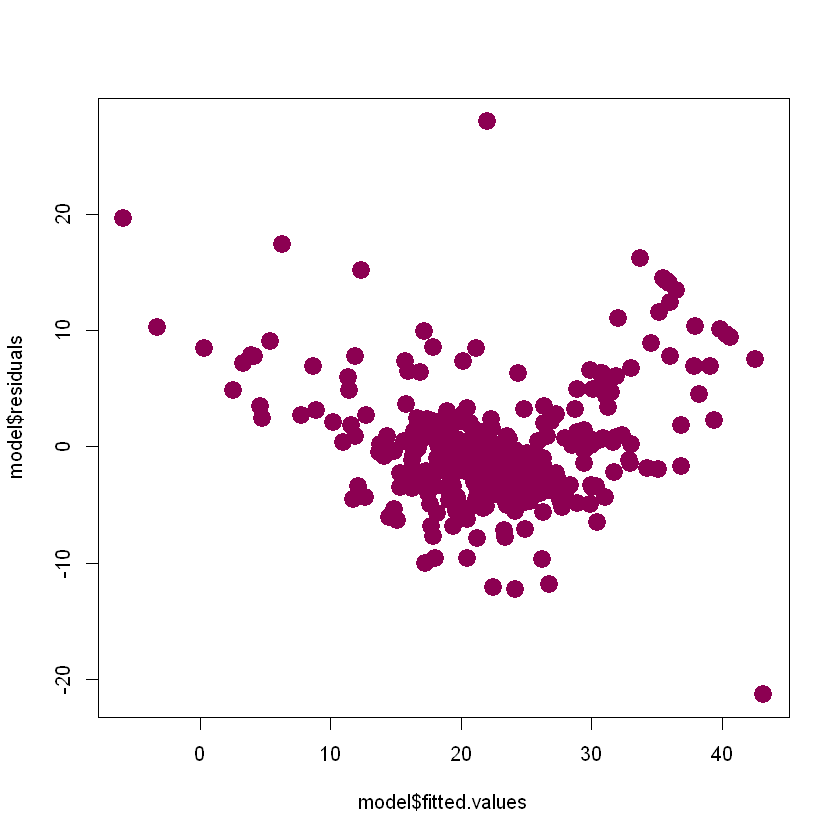

In [48]:
plot(model$fitted.values , model$residuals , pch =19,col ="#8c0052", cex=2 )

bptest(model)

#### No autocorrelation

In [49]:
dwtest(model)


	Durbin-Watson test

data:  model
DW = 1.0982, p-value = 6.209e-16
alternative hypothesis: true autocorrelation is greater than 0


#### Absence of outliers

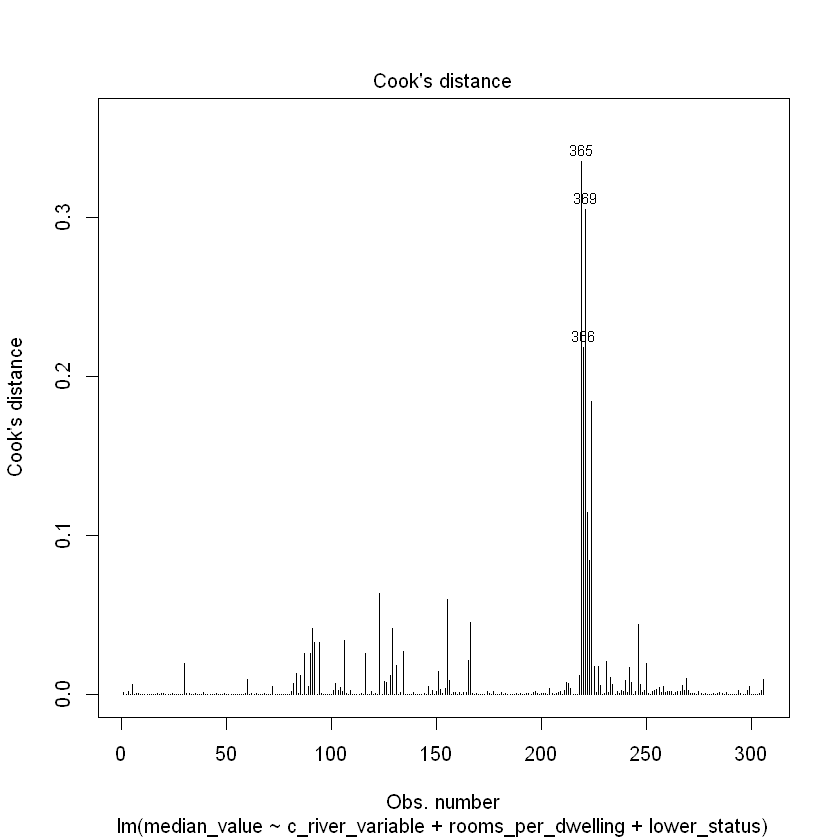

In [50]:
plot(model, 4)

We can see that only the homoscedasticity requirement is met:
* **Normality of residuals:** the Lilliefors test returned a p-value below 0.05, so we reject the null hypothesis that the residuals are normally distributed.
* **Homoscedasticity:** the Breusch-Pagan test returned a p-value above 0.05, so we cannot reject the null hypothesis that the error terms have constant variance.
* **No autocorrelation:** the Durbin-Watson test returned a p-value below 0.05, so we reject the null hypothesis that the error terms from different observations are uncorrelated.
* **Absence of outliers:** the Cook's distance plot shows that points 369, 366, and 375 are particularly prominent outliers.

We will now try to improve our regression by removing these influential outliers.

In [51]:
rows_to_remove <- which(rownames(data_train) %in% c("366", "369", "365"))
data_train_clean <- data_train[-rows_to_remove, ]

# check the number of rows before and after cleaning
nrow(data_train)
nrow(data_train_clean)

[1] 306

[1] 303

In [52]:
# train the model with clean data without the main outliers
model_clean <- lm(median_value ~ c_river_variable + rooms_per_dwelling + lower_status, data = data_train_clean)
summary(model_clean)


Call:
lm(formula = median_value ~ c_river_variable + rooms_per_dwelling + 
    lower_status, data = data_train_clean)

Residuals:
     Min       1Q   Median       3Q      Max 
-13.5682  -3.0631  -0.3814   2.4888  20.2012 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)        -12.16777    3.78031  -3.219  0.00143 ** 
c_river_variable     4.42174    1.10769   3.992 8.25e-05 ***
rooms_per_dwelling   6.58275    0.52701  12.491  < 2e-16 ***
lower_status        -0.56552    0.05334 -10.602  < 2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 4.962 on 299 degrees of freedom
Multiple R-squared:  0.7191,	Adjusted R-squared:  0.7163 
F-statistic: 255.2 on 3 and 299 DF,  p-value: < 2.2e-16


By removing the 3 main outliers, we improved the R-squared to 71.91% (it was 66.34% before).

### Predictions

R2,RMSE,MAE
<dbl>,<dbl>,<dbl>
0.6300259,5.455781,3.780821


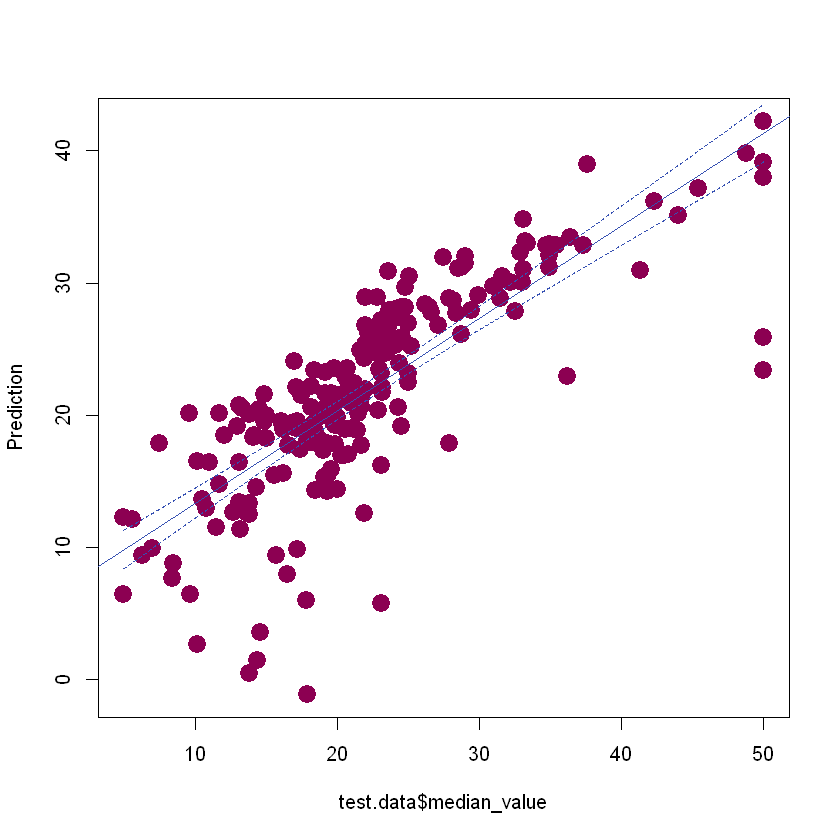

In [53]:
prediction = predict(model_clean, data_test)

plot(data_test$median_value, prediction, xlab="test.data$median_value", ylab="Prediction", pch =19,col ="#8c0052", cex=2)

lm.out = lm(prediction ~ median_value, data = data_test)
newx = seq(min(data_test$median_value),max(data_test$median_value),by = 0.05)
conf_interval = predict(lm.out, newdata=data.frame(median_value=newx), interval="confidence", level = 0.95)
abline(lm.out, col = "#3650b2")

lines(newx, conf_interval[,2], col="#3650b2", lty=2)
lines(newx, conf_interval[,3], col="#3650b2", lty=2)

data.frame( R2 = R2(prediction, data_test$median_value),
            RMSE = RMSE(prediction, data_test$median_value),
            MAE = MAE(prediction, data_test$median_value))

After making the predictions, we can see that our model does not suffer from *overfitting*; it performs well on data that were not used for training because the R-squared has remained fairly stable (71.94% in training versus 63.00% in testing).

We also obtained an RMSE of approximately 5.456, slightly higher than the RSE (4.962). Regarding the MAE, we obtained 3.78, meaning that our predictions deviate from the actual house value by an average of 3,780 USD. This is a good indicator because there is no large deviation considering the median price (22,530 USD) and the fact that we did not use many variables in the regression.

## 6. Conclusions

In summary, we studied our Boston house-price dataset and identified two variables related to `median_value`:
* `rooms_per_dwelling`: average number of rooms per dwelling. As it increased, the price increased.
* `lower_status`: percentage of the low-income population. As it increased, the price decreased.

We also studied `c_river_variable` and `highway_index`, finding that both had a statistically significant influence. However, when building our regression model, the former produced better results, probably because whether a house is near the river helps explain price increases or decreases.

Next, we trained and tested our model and obtained good results: it did not perform poorly on new data after training, and the deviation of the predictions was not very high. Nevertheless, not all the requirements that guarantee good performance of a linear regression were met (only homoscedasticity was satisfied), which may compromise our model.

We can therefore conclude that we created a model that predicts reasonably well using the few variables selected. However, we do not know whether it would be the best option in real life, since house price is a very complex variable and we would be limiting its prediction considerably with such a simple regression.